**DESCARGAR IMAGENES**

In [ ]:
# ================================================================
# DESCARGA DE IMÁGENES SENTINEL-2 PARA BENCHMARKING DE GFMs
# ================================================================

# --- 1. Instalación de dependencias ---
!pip install earthengine-api geemap pandas rasterio -q

# --- 2. Importar librerías ---
import ee
import pandas as pd
import time
import os
import re
import unicodedata
from google.colab import drive

# --- 3. Montar Google Drive ---
drive.mount('/content/drive')

# --- 4. Inicializar GEE ---
print("🔐 Inicializando Google Earth Engine...")
try:
    ee.Initialize(project='proyecto-puno')
    print("✅ GEE inicializado correctamente")
except Exception as e:
    print("⚠️ Primera vez usando GEE. Autenticando...")
    ee.Authenticate()
    ee.Initialize(project='proyecto-puno')
    print("✅ GEE inicializado correctamente")

# ================================================================
# CONFIGURACIÓN METODOLÓGICA
# ================================================================

CONFIG = {
    # Temporal (alineado con Mapa de Pobreza 2018)
    'fecha_inicio': '2018-01-01',
    'fecha_fin': '2018-12-31',
    'ventana_alternativa': ('2017-06-01', '2018-12-31'),

    # Espacial
    'buffer_metros': 500,
    'escala': 10,

    # Espectral (12 bandas para SatMAE)
    'bandas': ['B1', 'B2', 'B3', 'B4', 'B5', 'B6', 'B7',
           'B8', 'B8A', 'B9', 'B11', 'B12'],
    # Calidad
    'nubes_max': 20,
    'composite': 'median',

    # Exportación
    'formato': 'GeoTIFF',
    'carpeta_drive': 'GEE_Puno_2018',
    'prefix': 'Puno_2018_',
    'max_pixels': 1e9
}

print("\n" + "="*60)
print("📋 METODOLOGÍA DE DESCARGA DOCUMENTADA")
print("="*60)
print(f"   📅 Año: 2018 (alineado con etiquetas de pobreza)")
print(f"   📅 Ventana: {CONFIG['fecha_inicio']} a {CONFIG['fecha_fin']}")
print(f"   ☁️  Nubes máximas: {CONFIG['nubes_max']}% ")
print(f"   📐 Resolución: {CONFIG['escala']} m")
print(f"   🎨 Bandas: {len(CONFIG['bandas'])} bandas (todas Sentinel-2)")
print(f"   📏 Buffer: {CONFIG['buffer_metros']} m")
print(f"   📁 Carpeta Drive: {CONFIG['carpeta_drive']}")
print("="*60 + "\n")

# --- 5. Función para limpiar nombres de archivos ---
def limpiar_nombre(texto):
    """Limpia caracteres especiales para nombres de archivo."""
    texto = unicodedata.normalize('NFKD', texto)
    texto = texto.encode('ASCII', 'ignore').decode('utf-8')
    texto = re.sub(r'[^a-zA-Z0-9_]', '_', texto)
    texto = re.sub(r'_+', '_', texto)
    return texto

# --- 6. Función para máscara de nubes por píxel ---
def mask_s2_clouds(image):
    """Máscara de nubes y cirrus para Sentinel-2."""
    qa = image.select('QA60')
    cloudBitMask = 1 << 10
    cirrusBitMask = 1 << 11
    mask = qa.bitwiseAnd(cloudBitMask).eq(0).And(
           qa.bitwiseAnd(cirrusBitMask).eq(0))
    return image.updateMask(mask)

# --- 7. Cargar CSV de distritos ---
print("📂 Cargando archivo CSV...")
CSV_PATH = '/content/drive/MyDrive/DL_DATASET_DISTRITOS/dataset_distritos.csv'

try:
    df = pd.read_csv(CSV_PATH)
    print(f"✅ {len(df)} distritos cargados correctamente")
except FileNotFoundError:
    print("⚠️ Archivo no encontrado. Sube el archivo manualmente.")
    from google.colab import files
    uploaded = files.upload()
    df = pd.read_csv(list(uploaded.keys())[0])
    print(f"✅ {len(df)} distritos cargados")

# Verificar columnas
columnas_requeridas = ['distrito', 'lat', 'lon', 'ubigeo']
for col in columnas_requeridas:
    if col not in df.columns:
        raise ValueError(f"❌ Falta la columna '{col}' en el CSV")

# --- 8. Función principal de exportación ---
def exportar_imagen(fila, idx, total, config=CONFIG):
    """Exporta imagen Sentinel-2 para un distrito."""

    distrito = fila['distrito']
    lat = fila['lat']
    lon = fila['lon']
    ubigeo = str(fila['ubigeo']).zfill(6)

    print(f"\n[{idx+1}/{total}] 📍 Procesando: {distrito} ({ubigeo})")
    print(f"   Coordenadas: {lat:.4f}, {lon:.4f}")

    resultado = {
        'ubigeo': ubigeo,
        'distrito': distrito,
        'estado': 'pendiente',
        'archivo': '',
        'num_imagenes': 0,
        'ventana_usada': '2018',
        'error': ''
    }

    # Crear punto y región
    point = ee.Geometry.Point([lon, lat])
    region = point.buffer(config['buffer_metros'])

    # Obtener colección con máscara de nubes
    collection = (ee.ImageCollection('COPERNICUS/S2_SR_HARMONIZED')
                  .filterBounds(point)
                  .filterDate(config['fecha_inicio'], config['fecha_fin'])
                  .filter(ee.Filter.lt('CLOUDY_PIXEL_PERCENTAGE', config['nubes_max']))
                  .map(mask_s2_clouds))

    size = collection.size().getInfo()
    print(f"   📸 Imágenes disponibles (2018): {size}")
    resultado['num_imagenes'] = size

    # Si no hay imágenes, usar ventana alternativa
    if size == 0:
        print(f"   ⚠️  No hay imágenes sin nubes para {distrito}")
        print(f"   🔄 Intentando ventana alternativa: 2017-06 a 2018-12...")

        collection_alt = (ee.ImageCollection('COPERNICUS/S2_SR_HARMONIZED')
                         .filterBounds(point)
                         .filterDate(config['ventana_alternativa'][0],
                                    config['ventana_alternativa'][1])
                         .filter(ee.Filter.lt('CLOUDY_PIXEL_PERCENTAGE', config['nubes_max']))
                         .map(mask_s2_clouds))

        size_alt = collection_alt.size().getInfo()
        print(f"   📸 Imágenes en ventana alternativa: {size_alt}")

        if size_alt == 0:
            print(f"   ❌ No hay imágenes disponibles para {distrito}")
            resultado['estado'] = 'fallido_sin_imagenes'
            return resultado

        collection = collection_alt
        resultado['ventana_usada'] = '2017-06_a_2018-12'
        resultado['num_imagenes'] = size_alt

    # Crear composite mediano
    image = collection.median().clip(region)

    # Seleccionar bandas y escalar (CORREGIDO: divide(10000) para Sentinel-2)
    image_bands = image.select(config['bandas'])
    image_scaled = image_bands.divide(10000)  # ✅ Factor de escala correcto

    # Nombre del archivo (con limpieza)
    nombre_limpio = limpiar_nombre(distrito)
    nombre_archivo = f"{config['prefix']}{ubigeo}_{nombre_limpio}"
    resultado['archivo'] = nombre_archivo

    # Exportar
    try:
        task = ee.batch.Export.image.toDrive(
            image=image_scaled,
            description=f"Sentinel2_2018_{ubigeo}",
            folder=config['carpeta_drive'],
            fileNamePrefix=nombre_archivo,
            scale=config['escala'],
            region=region,  # ✅ Usar Geometry directamente
            fileFormat=config['formato'],
            maxPixels=config['max_pixels']
        )

        task.start()
        print(f"   ✅ Tarea iniciada: {nombre_archivo}")
        resultado['estado'] = 'iniciada'
        return resultado

    except Exception as e:
        print(f"   ❌ Error al exportar {distrito}: {str(e)}")
        resultado['estado'] = 'error'
        resultado['error'] = str(e)
        return resultado

# --- 8.5 Función para checkpoint ---
def cargar_checkpoint():
    """Carga el progreso guardado si existe."""
    checkpoint_path = '/content/drive/MyDrive/DL_DATASET_DISTRITOS/checkpoint.csv'

    if os.path.exists(checkpoint_path):
        checkpoint = pd.read_csv(checkpoint_path)
        # Convert ubigeo in checkpoint to string for consistent comparison
        # Mark any 'iniciada' tasks as 'completada' for the next run start
        checkpoint.loc[checkpoint['estado'] == 'iniciada', 'estado'] = 'completada'
        procesados_ubigeos = checkpoint[checkpoint['estado'].isin(['completada'])]['ubigeo'].astype(str).tolist()
        print(f"📌 Checkpoint encontrado: {len(procesados_ubigeos)} distritos ya procesados")
        return checkpoint # Return the full checkpoint DF
    else:
        print("📌 No hay checkpoint. Procesando todos los distritos...")
        return pd.DataFrame(columns=['ubigeo', 'distrito', 'estado', 'archivo', 'num_imagenes', 'ventana_usada', 'error']) # Return empty DF

# --- 9. Ejecutar exportación CON CHECKPOINT ---
print("\n" + "="*60)
print("🚀 INICIANDO EXPORTACIÓN DE IMÁGENES")
print("="*60)

# Cargar checkpoint existente
df_checkpoint_existente = cargar_checkpoint()
procesados_ubigeos = df_checkpoint_existente['ubigeo'].astype(str).tolist()

# Filtrar distritos no procesados
df_pendientes = df[~df['ubigeo'].astype(str).isin(procesados_ubigeos)]

print(f"   📍 Total de distritos: {len(df)}")
print(f"   ✅ Ya procesados: {len(procesados_ubigeos)}")
print(f"   ⏳ Pendientes: {len(df_pendientes)}")
print("="*60 + "\n")

# Inicializar registros para los distritos pendientes en este run
registros_nuevos = []
tiempo_inicio = time.time()

# Solo iterar si hay distritos pendientes
if not df_pendientes.empty:
    for idx, row in df_pendientes.iterrows():
        resultado = exportar_imagen(row, idx, len(df), CONFIG) # Pass len(df) for total count correctly
        registros_nuevos.append(resultado)

        # Guardar checkpoint CADA 5 distritos o al final de la iteración
        if (idx + 1) % 5 == 0 or (idx + 1) == len(df_pendientes):
            df_registros_nuevos = pd.DataFrame(registros_nuevos)
            # Combinar el checkpoint existente con los nuevos registros
            df_combinado = pd.concat([df_checkpoint_existente, df_registros_nuevos]).drop_duplicates(subset=['ubigeo'], keep='last').reset_index(drop=True)
            checkpoint_path = '/content/drive/MyDrive/DL_DATASET_DISTRITOS/checkpoint.csv'
            df_combinado.to_csv(checkpoint_path, index=False)
            print(f"💾 Checkpoint guardado ({len(df_combinado)} distritos totales procesados)")

        time.sleep(2)
else:
    print("🎉 No hay distritos pendientes. Todos han sido procesados.")

# Después del bucle, consolidar los resultados finales
if not df_pendientes.empty:
    df_registros_nuevos_final = pd.DataFrame(registros_nuevos)
    df_resultados_final = pd.concat([df_checkpoint_existente, df_registros_nuevos_final]).drop_duplicates(subset=['ubigeo'], keep='last').reset_index(drop=True)
else:
    df_resultados_final = df_checkpoint_existente

checkpoint_path = '/content/drive/MyDrive/DL_DATASET_DISTRITOS/checkpoint.csv'
df_resultados_final.to_csv(checkpoint_path, index=False) # Final save of consolidated results
print("💾 Checkpoint final y resultados consolidados guardados.")

tiempo_total = time.time() - tiempo_inicio

# --- 10. Guardar CSV con resultados (ADAPTADO) ---
# df_resultados is now df_resultados_final, already saved as checkpoint
print(f"\n✅ CSV de resultados final guardado en: {checkpoint_path}")

# --- 11. Estadísticas finales (ADAPTADO) ---
print("\n" + "="*60)
print("📊 RESUMEN FINAL DE EXPORTACIÓN")
print("="*60)

estados = df_resultados_final['estado'].value_counts() # Use df_resultados_final
for estado, count in estados.items():
    print(f"   {estado}: {count}")

print(f"\n   ⏱️  Tiempo total del RUN actual: {tiempo_total/60:.1f} minutos") # Clarify this run's time
if len(df_pendientes) > 0:
    print(f"   ⏱️  Promedio por distrito (solo este run): {tiempo_total/len(df_pendientes):.1f} segundos")
else:
    print("   ⏱️  No se procesaron nuevos distritos en este run.")

# Distritos que usaron ventana alternativa
alt = df_resultados_final[df_resultados_final['ventana_usada'] == '2017-06_a_2018-12'] # Use df_resultados_final
if len(alt) > 0:
    print(f"\n⚠️  Distritos que usaron ventana alternativa ({len(alt)}):")
    for _, row in alt.iterrows():
        print(f"   - {row['distrito']} ({row['ubigeo']})")

# Distritos fallidos
fallidos = df_resultados_final[df_resultados_final['estado'] == 'fallido_sin_imagenes'] # Use df_resultados_final
if len(fallidos) > 0:
    print(f"\n❌ Distritos sin imágenes ({len(fallidos)}):")
    for _, row in fallidos.iterrows():
        print(f"   - {row['distrito']} ({row['ubigeo']})")

print("\n" + "="*60)
print("📋 PRÓXIMOS PASOS")
print("="*60)
print("1. Revisa el progreso en: https://code.earthengine.google.com/tasks")
print(f"2. Las imágenes aparecerán en Google Drive > {CONFIG['carpeta_drive']}")
print("3. Una vez descargadas, estarán listas para la extracción de embeddings")
print("4. Ejecuta el siguiente notebook para el entrenamiento de los modelos")
print("="*60)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
🔐 Inicializando Google Earth Engine...
✅ GEE inicializado correctamente

📋 METODOLOGÍA DE DESCARGA DOCUMENTADA
   📅 Año: 2018 (alineado con etiquetas de pobreza)
   📅 Ventana: 2018-01-01 a 2018-12-31
   ☁️  Nubes máximas: 20% 
   📐 Resolución: 10 m
   🎨 Bandas: 12 bandas (todas Sentinel-2)
   📏 Buffer: 500 m
   📁 Carpeta Drive: GEE_Puno_2018

📂 Cargando archivo CSV...
✅ 110 distritos cargados correctamente

🚀 INICIANDO EXPORTACIÓN DE IMÁGENES
📌 No hay checkpoint. Procesando todos los distritos...
   📍 Total de distritos: 110
   ✅ Ya procesados: 0
   ⏳ Pendientes: 110


[1/110] 📍 Procesando: PUNO (210101)
   Coordenadas: -15.8406, -70.0280
   📸 Imágenes disponibles (2018): 17
   ✅ Tarea iniciada: Puno_2018_210101_PUNO

[2/110] 📍 Procesando: ACORA (210102)
   Coordenadas: -15.9756, -69.7956
   📸 Imágenes disponibles (2018): 11
   ✅ Tarea iniciada: Puno_2018_210

   📸 Imágenes disponibles (2018): 41
   ✅ Tarea iniciada: Puno_2018_210605_PUSI

[58/110] 📍 Procesando: ROSASPATA (210606)
   Coordenadas: -15.2345, -69.5273
   📸 Imágenes disponibles (2018): 4
   ✅ Tarea iniciada: Puno_2018_210606_ROSASPATA

[59/110] 📍 Procesando: TARACO (210607)
   Coordenadas: -15.2978, -69.9783
   📸 Imágenes disponibles (2018): 10
   ✅ Tarea iniciada: Puno_2018_210607_TARACO

[60/110] 📍 Procesando: VILQUE CHICO (210608)
   Coordenadas: -15.2143, -69.6891
   📸 Imágenes disponibles (2018): 4
   ✅ Tarea iniciada: Puno_2018_210608_VILQUE_CHICO
💾 Checkpoint guardado (60 distritos totales procesados)

[61/110] 📍 Procesando: LAMPA (210701)
   Coordenadas: -15.3636, -70.3668
   📸 Imágenes disponibles (2018): 17
   ✅ Tarea iniciada: Puno_2018_210701_LAMPA

[62/110] 📍 Procesando: CABANILLA (210702)
   Coordenadas: -15.6203, -70.3459
   📸 Imágenes disponibles (2018): 25
   ✅ Tarea iniciada: Puno_2018_210702_CABANILLA

[63/110] 📍 Procesando: CALAPUJA (210703)
   Coordenadas: -

**RECUPERAR LOS FALLIDOS**

In [ ]:
# --- RECUPERAR DISTRITOS FALLIDOS (VERSIÓN DEFINITIVA) ---
print("\n" + "="*60)
print("🔄 RECUPERANDO DISTRITOS FALLIDOS")
print("="*60)

# 1. Cargar checkpoint asegurando formato de ubigeo
checkpoint_path = '/content/drive/MyDrive/DL_DATASET_DISTRITOS/checkpoint.csv'
df_resultados = pd.read_csv(checkpoint_path)

# ✅ CONVERTIR UBIGEO A STRING DE 6 DÍGITOS EN AMBOS DATAFRAMES
df_resultados['ubigeo_str'] = df_resultados['ubigeo'].astype(str).str.zfill(6)
df['ubigeo_str'] = df['ubigeo'].astype(str).str.zfill(6)

# 2. Obtener lista de ubigeos fallidos (como string de 6 dígitos)
fallidos_ubigeo = df_resultados[df_resultados['estado'] == 'fallido_sin_imagenes']['ubigeo_str'].tolist()
print(f"📋 Distritos fallidos: {len(fallidos_ubigeo)}")
print(f"   Ejemplo: {fallidos_ubigeo[:3]}")

# 3. Filtrar dataset original usando ubigeo_str
df_fallidos = df[df['ubigeo_str'].isin(fallidos_ubigeo)].copy()
print(f"🔄 Distritos a recuperar: {len(df_fallidos)}")

# 4. Verificar coincidencia
if len(df_fallidos) == 0:
    print("\n⚠️ No se encontraron coincidencias. Verificando...")

    # Mostrar algunos ubigeos de cada lado
    print(f"\n   Ubigeos fallidos (primeros 5): {fallidos_ubigeo[:5]}")
    print(f"   Ubigeos en dataset (primeros 5): {df['ubigeo_str'].iloc[:5].tolist()}")

    # Buscar intersección
    intersection = set(fallidos_ubigeo) & set(df['ubigeo_str'].tolist())
    print(f"   Intersección: {len(intersection)} ubigeos coinciden")

    if len(intersection) == 0:
        print("\n❌ ¡Los ubigeos no coinciden! Verifica que el CSV tenga los mismos códigos.")
        print("   Ejecuta este diagnóstico para más detalles:")
        print("   - Ubigeos en checkpoint (fallidos):", fallidos_ubigeo)
        print("   - Ubigeos en dataset:", df['ubigeo'].astype(str).str.zfill(6).tolist()[:10])

    # Si no hay coincidencias, mostrar resumen y salir
    print("\n📊 ESTADO ACTUAL:")
    print(df_resultados['estado'].value_counts())

else:
    # 5. Configuración ampliada para recuperación
    CONFIG_RECUPERACION = CONFIG.copy()
    CONFIG_RECUPERACION['fecha_inicio'] = '2017-01-01'
    CONFIG_RECUPERACION['fecha_fin'] = '2019-12-31'
    CONFIG_RECUPERACION['nubes_max'] = 50  # Más tolerante

    print(f"\n📅 Ventana: 2017-01-01 a 2019-12-31")
    print(f"☁️ Nubes máximas: 50%")
    print("="*60)

    # 6. Recuperar distritos
    recuperados = []
    for idx, row in df_fallidos.iterrows():
        print(f"\n📍 [{idx+1}/{len(df_fallidos)}] {row['distrito']} ({row['ubigeo_str']})")
        print(f"   Coordenadas: {row['lat']:.4f}, {row['lon']:.4f}")

        resultado = exportar_imagen(row, idx, len(df_fallidos), CONFIG_RECUPERACION)
        recuperados.append(resultado)
        time.sleep(3)

    # 7. Guardar resultados
    df_recuperados = pd.DataFrame(recuperados)
    df_recuperados.to_csv('/content/drive/MyDrive/DL_DATASET_DISTRITOS/recuperados.csv', index=False)

    # 8. Actualizar checkpoint
    df_combinado = pd.concat([df_resultados, df_recuperados]).drop_duplicates(subset=['ubigeo'], keep='last')
    df_combinado.to_csv(checkpoint_path, index=False)

    # 9. Resultados
    print("\n" + "="*60)
    print("📊 RESULTADOS DE RECUPERACIÓN")
    print("="*60)
    print(df_recuperados['estado'].value_counts())

    aun_fallidos = df_recuperados[df_recuperados['estado'] == 'fallido_sin_imagenes']
    if len(aun_fallidos) > 0:
        print(f"\n❌ Aún sin imágenes ({len(aun_fallidos)}):")
        for _, row in aun_fallidos.iterrows():
            print(f"   - {row['distrito']} ({row['ubigeo']})")
    else:
        print("\n✅ ¡Todos los distritos recuperados exitosamente!")


🔄 RECUPERANDO DISTRITOS FALLIDOS
📋 Distritos fallidos: 22
   Ejemplo: ['210209', '210301', '210302']
🔄 Distritos a recuperar: 22

📅 Ventana: 2017-01-01 a 2019-12-31
☁️ Nubes máximas: 50%

📍 [24/22] POTONI (210209)
   Coordenadas: -14.3899, -70.1047

[24/22] 📍 Procesando: POTONI (210209)
   Coordenadas: -14.3899, -70.1047
   📸 Imágenes disponibles (2018): 74
   ✅ Tarea iniciada: Puno_2018_210209_POTONI

📍 [31/22] MACUSANI (210301)
   Coordenadas: -14.0684, -70.4314

[31/22] 📍 Procesando: MACUSANI (210301)
   Coordenadas: -14.0684, -70.4314
   📸 Imágenes disponibles (2018): 30
   ✅ Tarea iniciada: Puno_2018_210301_MACUSANI

📍 [32/22] AJOYANI (210302)
   Coordenadas: -14.2301, -70.2236

[32/22] 📍 Procesando: AJOYANI (210302)
   Coordenadas: -14.2301, -70.2236
   📸 Imágenes disponibles (2018): 74
   ✅ Tarea iniciada: Puno_2018_210302_AJOYANI

📍 [33/22] AYAPATA (210303)
   Coordenadas: -13.7770, -70.3227

[33/22] 📍 Procesando: AYAPATA (210303)
   Coordenadas: -13.7770, -70.3227
   📸 Imágen

**Código completo para limpiar todas las imágenes**

In [ ]:
# ============================================================
# LIMPIEZA MASIVA DE IMÁGENES SENTINEL-2
# Reemplaza NaN e Inf preservando la georreferenciación
# ============================================================

import os
import rasterio
import numpy as np
from google.colab import drive

drive.mount('/content/drive')

#--------------------------------------------------
# CARPETAS
#--------------------------------------------------

CARPETA_ENTRADA = "/content/drive/MyDrive/GEE_Puno_2018"

CARPETA_SALIDA = "/content/drive/MyDrive/GEE_Puno_2018_Limpias"

os.makedirs(CARPETA_SALIDA, exist_ok=True)

#--------------------------------------------------
# CONTADORES
#--------------------------------------------------

total_imagenes = 0

imagenes_con_nan = 0

pixeles_nan = 0

#--------------------------------------------------
# RECORRER TODAS LAS IMÁGENES
#--------------------------------------------------

for archivo in sorted(os.listdir(CARPETA_ENTRADA)):

    if not archivo.lower().endswith(".tif"):
        continue

    total_imagenes += 1

    ruta_entrada = os.path.join(CARPETA_ENTRADA, archivo)

    ruta_salida = os.path.join(CARPETA_SALIDA, archivo)

    with rasterio.open(ruta_entrada) as src:

        img = src.read()

        profile = src.profile.copy()

    n_nan = np.isnan(img).sum()

    n_inf = np.isinf(img).sum()

    if n_nan > 0 or n_inf > 0:

        imagenes_con_nan += 1

        pixeles_nan += n_nan

        img = np.nan_to_num(
            img,
            nan=0.0,
            posinf=0.0,
            neginf=0.0
        )

    with rasterio.open(
        ruta_salida,
        "w",
        **profile
    ) as dst:

        dst.write(img)

    print(
        f"{archivo:45s} | NaN={n_nan:6d} | Inf={n_inf:6d}"
    )

#--------------------------------------------------
# RESUMEN
#--------------------------------------------------

print("\n" + "="*70)

print("RESUMEN")

print("="*70)

print(f"Total imágenes          : {total_imagenes}")

print(f"Con NaN                 : {imagenes_con_nan}")

print(f"Total NaN encontrados   : {pixeles_nan}")

print(f"Carpeta salida          : {CARPETA_SALIDA}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Puno_2018_210101_PUNO.tif                     | NaN= 27948 | Inf=     0
Puno_2018_210102_ACORA.tif                    | NaN= 27912 | Inf=     0
Puno_2018_210103_AMANTANI.tif                 | NaN= 28140 | Inf=     0
Puno_2018_210104_ATUNCOLLA.tif                | NaN= 28092 | Inf=     0
Puno_2018_210105_CAPACHICA.tif                | NaN= 26868 | Inf=     0
Puno_2018_210106_CHUCUITO.tif                 | NaN= 29280 | Inf=     0
Puno_2018_210107_COATA.tif                    | NaN= 26904 | Inf=     0
Puno_2018_210108_HUATA.tif                    | NaN= 28080 | Inf=     0
Puno_2018_210109_MANAZO.tif                   | NaN= 27984 | Inf=     0
Puno_2018_210110_PAUCARCOLLA.tif              | NaN= 26820 | Inf=     0
Puno_2018_210111_PICHACANI.tif                | NaN= 27888 | Inf=     0
Puno_2018_210112_PLATERIA.tif                 | NaN= 28020 | Inf=     0
Puno_20

**Verificar que quedaron limpias**

In [ ]:
# ============================================================
# VERIFICACIÓN DEL DATASET LIMPIO
# ============================================================

import os
import rasterio
import numpy as np

CARPETA = "/content/drive/MyDrive/GEE_Puno_2018_Limpias"

imagenes_con_nan = 0

for archivo in sorted(os.listdir(CARPETA)):

    if archivo.endswith(".tif"):

        ruta = os.path.join(CARPETA, archivo)

        with rasterio.open(ruta) as src:

            img = src.read()

        nan = np.isnan(img).sum()

        inf = np.isinf(img).sum()

        if nan > 0 or inf > 0:

            imagenes_con_nan += 1

            print(
                archivo,
                "NaN:",
                nan,
                "Inf:",
                inf
            )

print("\n===================================")

if imagenes_con_nan == 0:

    print("✅ Todas las imágenes están limpias.")

else:

    print(f"⚠️ Hay {imagenes_con_nan} imágenes con problemas.")


✅ Todas las imágenes están limpias.


**LIMPIEZA FINAL**

In [ ]:
# ============================================================
# LIMPIEZA FINAL DEL DATASET
# NaN -> 0
# Inf -> 0
# float64 -> float32
# ============================================================

import os
import numpy as np
import rasterio

CARPETA_ENTRADA = "/content/drive/MyDrive/GEE_Puno_2018_Limpias"

CARPETA_SALIDA = "/content/drive/MyDrive/GEE_Puno_2018_Final"

os.makedirs(CARPETA_SALIDA, exist_ok=True)

for archivo in sorted(os.listdir(CARPETA_ENTRADA)):

    if not archivo.endswith(".tif"):
        continue

    ruta_in = os.path.join(CARPETA_ENTRADA, archivo)
    ruta_out = os.path.join(CARPETA_SALIDA, archivo)

    with rasterio.open(ruta_in) as src:

        img = src.read()

        profile = src.profile.copy()

    # Eliminar NaN e Inf
    img = np.nan_to_num(
        img,
        nan=0.0,
        posinf=0.0,
        neginf=0.0
    )

    # Convertir a float32
    img = img.astype(np.float32)

    # Actualizar perfil
    profile.update(dtype=rasterio.float32)

    with rasterio.open(
        ruta_out,
        "w",
        **profile
    ) as dst:

        dst.write(img)

print("✅ Dataset final generado correctamente.")

✅ Dataset final generado correctamente.


**DESPUES DE LA LIMPIEZA FINAL, VERFICAMOS**

In [ ]:
import os
import rasterio
import numpy as np

CARPETA = "/content/drive/MyDrive/GEE_Puno_2018_Final"

for archivo in sorted(os.listdir(CARPETA)):

    if archivo.endswith(".tif"):

        ruta = os.path.join(CARPETA, archivo)

        with rasterio.open(ruta) as src:

            img = src.read()

        print(
            archivo,
            img.dtype,
            np.isnan(img).sum(),
            np.isinf(img).sum()
        )

        break

Puno_2018_210101_PUNO.tif float32 0 0


# **EXTRACCION DE CARACTERISTICAS**

# **RESNET-50**

In [ ]:
# ================================================================
# NOTEBOOK 3: EXTRACCIÓN DE EMBEDDINGS - ResNet50
# Versión limpia y autocontenida
# ================================================================

# --- 1. Instalación ---
!pip install rasterio torch torchvision pandas numpy tqdm -q

# --- 2. Imports ---
import os
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torchvision import models, transforms
from PIL import Image
import rasterio
from tqdm import tqdm
from google.colab import drive
import gc
import warnings
warnings.filterwarnings('ignore')

# --- 3. Montar Google Drive ---
drive.mount('/content/drive')

# --- 4. Configuración ---
CARPETA_IMAGENES = '/content/drive/MyDrive/GEE_Puno_2018_Final/'
CARPETA_SALIDA = '/content/drive/MyDrive/Embeddings_Puno_DesdeCero/'
CSV_DISTRITOS = '/content/drive/MyDrive/DL_DATASET_DISTRITOS/dataset_distritos.csv'

os.makedirs(CARPETA_SALIDA, exist_ok=True)

# --- 5. Cargar CSV para obtener UBIGEOs válidos ---
df = pd.read_csv(CSV_DISTRITOS)
df['ubigeo'] = df['ubigeo'].astype(str).str.zfill(6)
ubigeos_validos = set(df['ubigeo'])

print(f"📊 {len(df)} distritos en el CSV")
print(f"📂 Imágenes en: {CARPETA_IMAGENES}")

# --- 6. Listar archivos de imagen ---
archivos = [f for f in os.listdir(CARPETA_IMAGENES) if f.endswith('.tif')]
print(f"📸 {len(archivos)} archivos TIFF encontrados")

# --- 7. Función para extraer ubigeo del nombre ---
def extraer_ubigeo(nombre_archivo):
    try:
        partes = nombre_archivo.split('_')
        for parte in partes:
            if parte.isdigit() and len(parte) == 6:
                return parte
        return None
    except:
        return None

# --- 8. Filtrar solo los que están en el CSV ---
archivos_filtrados = []
for f in archivos:
    ubigeo = extraer_ubigeo(f)
    if ubigeo and ubigeo in ubigeos_validos:
        archivos_filtrados.append(f)

print(f"✅ {len(archivos_filtrados)} imágenes coinciden con el CSV")

# --- 9. Función para cargar imagen ---
def cargar_imagen(ruta):
    with rasterio.open(ruta) as src:
        img = src.read()  # (C, H, W)
        img = np.transpose(img, (1, 2, 0))  # (H, W, C)
        # RGB: B4=Red (3), B3=Green (2), B2=Blue (1)
        rgb = img[:, :, [3, 2, 1]]
        rgb = np.clip(rgb, 0, 1)
        return (rgb * 255).astype(np.uint8)

# --- 10. Transformaciones ---
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                        std=[0.229, 0.224, 0.225])
])

# --- 11. Cargar modelo ResNet50 ---
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f"🔧 Usando dispositivo: {device}")

print("🔵 Cargando ResNet50...")
model = models.resnet50(weights='IMAGENET1K_V1')
model.fc = nn.Identity()
model = model.to(device)
model.eval()

# --- 12. Extraer embeddings ---
embeddings_list = []
nombres_list = []
batch_size = 16

for i in tqdm(range(0, len(archivos_filtrados), batch_size), desc="Extrayendo embeddings"):
    batch_files = archivos_filtrados[i:i+batch_size]
    batch_tensors = []
    batch_names = []

    for archivo in batch_files:
        try:
            ruta = os.path.join(CARPETA_IMAGENES, archivo)
            rgb = cargar_imagen(ruta)
            pil_img = Image.fromarray(rgb)
            tensor = transform(pil_img).unsqueeze(0)
            batch_tensors.append(tensor)
            batch_names.append(archivo)
        except Exception as e:
            print(f"⚠️ Error en {archivo}: {e}")
            continue

    if not batch_tensors:
        continue

    batch_tensor = torch.cat(batch_tensors).to(device)

    with torch.no_grad():
        embeddings = model(batch_tensor)
        embeddings_list.append(embeddings.cpu().numpy())
        nombres_list.extend(batch_names)

    del batch_tensor
    torch.cuda.empty_cache()

# --- 13. Guardar resultados ---
if embeddings_list:
    embeddings_all = np.vstack(embeddings_list)
    np.save(os.path.join(CARPETA_SALIDA, 'ResNet50_embeddings.npy'), embeddings_all)
    np.save(os.path.join(CARPETA_SALIDA, 'ResNet50_nombres.npy'), np.array(nombres_list))

    print("\n" + "="*60)
    print("✅ EXTRACCIÓN ResNet50 COMPLETADA")
    print("="*60)
    print(f"Embeddings shape: {embeddings_all.shape}")
    print(f"Guardado en: {CARPETA_SALIDA}")
    print(f"NaN: {np.isnan(embeddings_all).sum()}")
    print(f"Inf: {np.isinf(embeddings_all).sum()}")
else:
    print("❌ No se generaron embeddings")

# --- 14. Liberar memoria ---
del model
torch.cuda.empty_cache()
gc.collect()
print("\n✅ Memoria liberada")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
📊 110 distritos en el CSV
📂 Imágenes en: /content/drive/MyDrive/GEE_Puno_2018_Final/
📸 110 archivos TIFF encontrados
✅ 110 imágenes coinciden con el CSV
🔧 Usando dispositivo: cuda
🔵 Cargando ResNet50...


Extrayendo embeddings: 100%|██████████| 7/7 [00:02<00:00,  2.41it/s]



✅ EXTRACCIÓN ResNet50 COMPLETADA
Embeddings shape: (110, 2048)
Guardado en: /content/drive/MyDrive/Embeddings_Puno_DesdeCero/
NaN: 0
Inf: 0

✅ Memoria liberada


# **DINOv2**

In [ ]:
# ================================================================
# NOTEBOOK 4: EXTRACCIÓN DE EMBEDDINGS - DINOv2
# Versión limpia y autocontenida
# ================================================================

# --- 1. Instalación ---
!pip install rasterio torch torchvision transformers tqdm -q

# --- 2. Imports ---
import os
import numpy as np
import pandas as pd
import torch
from PIL import Image
import rasterio
from tqdm import tqdm
from google.colab import drive
import gc
import warnings
warnings.filterwarnings('ignore')

from transformers import AutoImageProcessor, AutoModel

# --- 3. Montar Google Drive ---
drive.mount('/content/drive')

# --- 4. Configuración ---
CARPETA_IMAGENES = '/content/drive/MyDrive/GEE_Puno_2018_Final/'
CARPETA_SALIDA = '/content/drive/MyDrive/Embeddings_Puno_DesdeCero/'
CSV_DISTRITOS = '/content/drive/MyDrive/DL_DATASET_DISTRITOS/dataset_distritos.csv'

os.makedirs(CARPETA_SALIDA, exist_ok=True)

# --- 5. Cargar CSV para obtener UBIGEOs válidos ---
df = pd.read_csv(CSV_DISTRITOS)
df['ubigeo'] = df['ubigeo'].astype(str).str.zfill(6)
ubigeos_validos = set(df['ubigeo'])

print(f"📊 {len(df)} distritos en el CSV")
print(f"📂 Imágenes en: {CARPETA_IMAGENES}")

# --- 6. Listar archivos de imagen ---
archivos = [f for f in os.listdir(CARPETA_IMAGENES) if f.endswith('.tif')]
print(f"📸 {len(archivos)} archivos TIFF encontrados")

# --- 7. Función para extraer ubigeo del nombre ---
def extraer_ubigeo(nombre_archivo):
    try:
        partes = nombre_archivo.split('_')
        for parte in partes:
            if parte.isdigit() and len(parte) == 6:
                return parte
        return None
    except:
        return None

# --- 8. Filtrar solo los que están en el CSV ---
archivos_filtrados = []
for f in archivos:
    ubigeo = extraer_ubigeo(f)
    if ubigeo and ubigeo in ubigeos_validos:
        archivos_filtrados.append(f)

print(f"✅ {len(archivos_filtrados)} imágenes coinciden con el CSV")

# --- 9. Función para cargar imagen RGB ---
def cargar_imagen(ruta):
    with rasterio.open(ruta) as src:
        img = src.read().astype(np.float32)
        img = np.transpose(img, (1, 2, 0))
        rgb = img[:, :, [3, 2, 1]]
        rgb = np.clip(rgb, 0, 1)
        return (rgb * 255).astype(np.uint8)

# --- 10. Cargar modelo DINOv2 ---
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f"🔧 Usando dispositivo: {device}")

print("🟣 Cargando DINOv2...")
processor = AutoImageProcessor.from_pretrained("facebook/dinov2-base")
model = AutoModel.from_pretrained("facebook/dinov2-base")
model = model.to(device)
model.eval()

# --- 11. Extraer embeddings ---
embeddings_list = []
nombres_list = []
batch_size = 12

for i in tqdm(range(0, len(archivos_filtrados), batch_size), desc="Extrayendo DINOv2"):
    batch_files = archivos_filtrados[i:i+batch_size]
    batch_tensors = []
    batch_names = []

    for archivo in batch_files:
        try:
            ruta = os.path.join(CARPETA_IMAGENES, archivo)
            rgb = cargar_imagen(ruta)
            pil_img = Image.fromarray(rgb)
            inputs = processor(images=pil_img, return_tensors="pt")
            tensor = inputs['pixel_values'].squeeze(0).unsqueeze(0)
            batch_tensors.append(tensor)
            batch_names.append(archivo)
        except Exception as e:
            print(f"⚠️ Error en {archivo}: {e}")
            continue

    if not batch_tensors:
        continue

    batch_tensor = torch.cat(batch_tensors).to(device)

    with torch.no_grad():
        outputs = model(batch_tensor)
        embeddings = outputs.last_hidden_state[:, 0, :]
        embeddings_list.append(embeddings.cpu().numpy())
        nombres_list.extend(batch_names)

    del batch_tensor
    torch.cuda.empty_cache()

# --- 12. Guardar resultados ---
if embeddings_list:
    embeddings_all = np.vstack(embeddings_list)
    np.save(os.path.join(CARPETA_SALIDA, 'DINOv2_embeddings.npy'), embeddings_all)
    np.save(os.path.join(CARPETA_SALIDA, 'DINOv2_nombres.npy'), np.array(nombres_list))

    print("\n" + "="*60)
    print("✅ EXTRACCIÓN DINOv2 COMPLETADA")
    print("="*60)
    print(f"Embeddings shape: {embeddings_all.shape}")
    print(f"Guardado en: {CARPETA_SALIDA}")
    print(f"NaN: {np.isnan(embeddings_all).sum()}")
    print(f"Inf: {np.isinf(embeddings_all).sum()}")
else:
    print("❌ No se generaron embeddings")

# --- 13. Liberar memoria ---
del model, processor
torch.cuda.empty_cache()
gc.collect()
print("\n✅ Memoria liberada")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
📊 110 distritos en el CSV
📂 Imágenes en: /content/drive/MyDrive/GEE_Puno_2018_Final/
📸 110 archivos TIFF encontrados
✅ 110 imágenes coinciden con el CSV
🔧 Usando dispositivo: cuda
🟣 Cargando DINOv2...


preprocessor_config.json:   0%|          | 0.00/436 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/548 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  346MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

Extrayendo DINOv2: 100%|██████████| 10/10 [00:04<00:00,  2.32it/s]



✅ EXTRACCIÓN DINOv2 COMPLETADA
Embeddings shape: (110, 768)
Guardado en: /content/drive/MyDrive/Embeddings_Puno_DesdeCero/
NaN: 0
Inf: 0

✅ Memoria liberada


# **SATMAE**

In [ ]:
# ================================================================
# NOTEBOOK 5: EXTRACCIÓN DE EMBEDDINGS - ViT (SatMAE)
# Versión limpia y autocontenida
# ================================================================

# --- 1. Instalación ---
!pip install rasterio torch torchvision transformers tqdm -q

# --- 2. Imports ---
import os
import numpy as np
import pandas as pd
import torch
import rasterio
from tqdm import tqdm
from google.colab import drive
import gc
import warnings
warnings.filterwarnings('ignore')

from transformers import ViTModel

# --- 3. Montar Google Drive ---
drive.mount('/content/drive')

# --- 4. Configuración ---
CARPETA_IMAGENES = '/content/drive/MyDrive/GEE_Puno_2018_Final/'
CARPETA_SALIDA = '/content/drive/MyDrive/Embeddings_Puno_DesdeCero/'
CSV_DISTRITOS = '/content/drive/MyDrive/DL_DATASET_DISTRITOS/dataset_distritos.csv'

os.makedirs(CARPETA_SALIDA, exist_ok=True)

# --- 5. Cargar CSV para obtener UBIGEOs válidos ---
df = pd.read_csv(CSV_DISTRITOS)
df['ubigeo'] = df['ubigeo'].astype(str).str.zfill(6)
ubigeos_validos = set(df['ubigeo'])

print(f"📊 {len(df)} distritos en el CSV")
print(f"📂 Imágenes en: {CARPETA_IMAGENES}")

# --- 6. Listar archivos de imagen ---
archivos = [f for f in os.listdir(CARPETA_IMAGENES) if f.endswith('.tif')]
print(f"📸 {len(archivos)} archivos TIFF encontrados")

# --- 7. Función para extraer ubigeo del nombre ---
def extraer_ubigeo(nombre_archivo):
    try:
        partes = nombre_archivo.split('_')
        for parte in partes:
            if parte.isdigit() and len(parte) == 6:
                return parte
        return None
    except:
        return None

# --- 8. Filtrar solo los que están en el CSV ---
archivos_filtrados = []
for f in archivos:
    ubigeo = extraer_ubigeo(f)
    if ubigeo and ubigeo in ubigeos_validos:
        archivos_filtrados.append(f)

print(f"✅ {len(archivos_filtrados)} imágenes coinciden con el CSV")

# --- 9. Función para cargar RGB (sin percentiles problemáticos) ---
def cargar_rgb_sentinel2(ruta):
    with rasterio.open(ruta) as src:
        img = src.read()
        img = np.transpose(img, (1, 2, 0))
        # B2=Azul (1), B3=Verde (2), B4=Rojo (3)
        blue = img[:, :, 1]
        green = img[:, :, 2]
        red = img[:, :, 3]
        rgb = np.stack([red, green, blue], axis=2)
        rgb = np.clip(rgb, 0, 1)
        return rgb.astype(np.float32)

# --- 10. Cargar modelo ViT ---
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f"🔧 Usando dispositivo: {device}")

print("🟢 Cargando ViT-Large...")
model = ViTModel.from_pretrained("google/vit-large-patch16-224")
model = model.to(device)
model.eval()

# --- 11. Extraer embeddings ---
embeddings_list = []
nombres_list = []
batch_size = 4

for i in tqdm(range(0, len(archivos_filtrados), batch_size), desc="Extrayendo ViT"):
    batch_files = archivos_filtrados[i:i+batch_size]
    batch_tensors = []
    batch_names = []

    for archivo in batch_files:
        try:
            ruta = os.path.join(CARPETA_IMAGENES, archivo)
            rgb = cargar_rgb_sentinel2(ruta)

            tensor = torch.from_numpy(rgb).permute(2, 0, 1).unsqueeze(0).float()
            tensor = torch.nn.functional.interpolate(
                tensor, size=(224, 224), mode='bilinear', align_corners=False
            )
            tensor = torch.clamp(tensor, 0, 1)

            batch_tensors.append(tensor)
            batch_names.append(archivo)
        except Exception as e:
            print(f"⚠️ Error en {archivo}: {e}")
            continue

    if not batch_tensors:
        continue

    batch_tensor = torch.cat(batch_tensors).to(device)

    with torch.no_grad():
        outputs = model(batch_tensor)
        embeddings = outputs.last_hidden_state[:, 0, :]
        embeddings_list.append(embeddings.cpu().numpy())
        nombres_list.extend(batch_names)

    del batch_tensor
    torch.cuda.empty_cache()

# --- 12. Guardar resultados ---
if embeddings_list:
    embeddings_all = np.vstack(embeddings_list)
    np.save(os.path.join(CARPETA_SALIDA, 'ViT_embeddings.npy'), embeddings_all)
    np.save(os.path.join(CARPETA_SALIDA, 'ViT_nombres.npy'), np.array(nombres_list))

    print("\n" + "="*60)
    print("✅ EXTRACCIÓN ViT COMPLETADA")
    print("="*60)
    print(f"Embeddings shape: {embeddings_all.shape}")
    print(f"Guardado en: {CARPETA_SALIDA}")
    print(f"NaN: {np.isnan(embeddings_all).sum()}")
    print(f"Inf: {np.isinf(embeddings_all).sum()}")
else:
    print("❌ No se generaron embeddings")

# --- 13. Liberar memoria ---
del model
torch.cuda.empty_cache()
gc.collect()
print("\n✅ Memoria liberada")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
📊 110 distritos en el CSV
📂 Imágenes en: /content/drive/MyDrive/GEE_Puno_2018_Final/
📸 110 archivos TIFF encontrados
✅ 110 imágenes coinciden con el CSV
🔧 Usando dispositivo: cuda
🟢 Cargando ViT-Large...


config.json:   0%|          | 0.00/69.7k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B / 1.22GB            

pytorch_model.bin: downloading bytes:           |  0.00B            

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.22GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/390 [00:00<?, ?it/s]

[transformers] ViTModel LOAD REPORT from: google/vit-large-patch16-224
Key                 | Status     | 
--------------------+------------+-
classifier.bias     | UNEXPECTED | 
classifier.weight   | UNEXPECTED | 
pooler.dense.bias   | MISSING    | 
pooler.dense.weight | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Extrayendo ViT:   0%|          | 0/28 [00:00<?, ?it/s]

Extrayendo ViT:   4%|▎         | 1/28 [00:01<00:49,  1.82s/it]

Extrayendo ViT:   7%|▋         | 2/28 [00:02<00:30,  1.19s/it]

Extrayendo ViT:  11%|█         | 3/28 [00:03<00:21,  1.15it/s]

Extrayendo ViT:  14%|█▍        | 4/28 [00:03<00:19,  1.26it/s]

Extrayendo ViT:  18%|█▊        | 5/28 [00:04<00:17,  1.31it/s]

Extrayendo ViT:  21%|██▏       | 6/28 [00:04<00:14,  1.49it/s]

Extrayendo ViT:  25%|██


✅ EXTRACCIÓN ViT COMPLETADA
Embeddings shape: (110, 1024)
Guardado en: /content/drive/MyDrive/Embeddings_Puno_DesdeCero/
NaN: 0
Inf: 0

✅ Memoria liberada


**OPTUNA: OPTIMIZACIÓN DE HIPERPARÁMETROS**

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# ================================================================
# OPTUNA: OPTIMIZACIÓN DE HIPERPARÁMETROS
# ================================================================

!pip install optuna -q

import optuna, os
import numpy as np
import pandas as pd
from sklearn.model_selection import cross_val_score, KFold
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import Ridge
import xgboost as xgb
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import warnings
warnings.filterwarnings('ignore')

# --- Cargar datos ---
CARPETA_EMBEDDINGS = '/content/drive/MyDrive/Embeddings_Puno_DesdeCero/'
CSV_DISTRITOS = '/content/drive/MyDrive/DL_DATASET_DISTRITOS/dataset_distritos.csv'

embeddings_dict = {}
for modelo in ['ResNet50', 'DINOv2', 'ViT']:
    ruta = os.path.join(CARPETA_EMBEDDINGS, f'{modelo}_embeddings.npy')
    if os.path.exists(ruta):
        embeddings_dict[modelo] = np.load(ruta)

df_pobreza = pd.read_csv(CSV_DISTRITOS)
df_pobreza['ubigeo'] = df_pobreza['ubigeo'].astype(str).str.zfill(6)
y = df_pobreza['pob_pct'].values

# --- Preparar X (usaremos PCA 50) ---
def preparar_X(emb, n_components=50):
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(emb)
    pca = PCA(n_components=min(n_components, emb.shape[0]-1), random_state=42)
    return pca.fit_transform(X_scaled)

cv = KFold(n_splits=5, shuffle=True, random_state=42)

# ================================================================
# 1.1 RANDOM FOREST CON OPTUNA
# ================================================================

def objective_rf(trial):
    params = {
        'n_estimators': trial.suggest_int('n_estimators', 50, 500),
        'max_depth': trial.suggest_int('max_depth', 3, 15),
        'min_samples_split': trial.suggest_int('min_samples_split', 2, 10),
        'min_samples_leaf': trial.suggest_int('min_samples_leaf', 1, 8),
        'max_features': trial.suggest_float('max_features', 0.2, 1.0),
        'random_state': 42
    }
    model = RandomForestRegressor(**params, n_jobs=-1)
    scores = cross_val_score(model, X, y, cv=cv, scoring='r2')
    return scores.mean()

print("\n🔵 OPTUNA - Random Forest")
print("="*60)

mejores_rf = {}

for nombre, emb in embeddings_dict.items():
    print(f"\n📊 {nombre}")
    X = preparar_X(emb)

    study = optuna.create_study(direction='maximize', study_name=f'rf_{nombre}')
    study.optimize(objective_rf, n_trials=30, show_progress_bar=True)

    mejores_rf[nombre] = study.best_params
    print(f"  Mejores params: {study.best_params}")
    print(f"  Mejor R²: {study.best_value:.4f}")

# ================================================================
# 1.2 XGBoost CON OPTUNA
# ================================================================

def objective_xgb(trial):
    params = {
        'n_estimators': trial.suggest_int('n_estimators', 50, 500),
        'max_depth': trial.suggest_int('max_depth', 2, 10),
        'learning_rate': trial.suggest_float('learning_rate', 0.005, 0.3, log=True),
        'subsample': trial.suggest_float('subsample', 0.5, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.5, 1.0),
        'min_child_weight': trial.suggest_int('min_child_weight', 1, 10),
        'reg_alpha': trial.suggest_float('reg_alpha', 1e-5, 10.0, log=True),
        'reg_lambda': trial.suggest_float('reg_lambda', 1e-5, 10.0, log=True),
        'random_state': 42,
        'verbosity': 0
    }
    model = xgb.XGBRegressor(**params)
    scores = cross_val_score(model, X, y, cv=cv, scoring='r2')
    return scores.mean()

print("\n🟣 OPTUNA - XGBoost")
print("="*60)

mejores_xgb = {}

for nombre, emb in embeddings_dict.items():
    print(f"\n📊 {nombre}")
    X = preparar_X(emb)

    study = optuna.create_study(direction='maximize', study_name=f'xgb_{nombre}')
    study.optimize(objective_xgb, n_trials=30, show_progress_bar=True)

    mejores_xgb[nombre] = study.best_params
    print(f"  Mejores params: {study.best_params}")
    print(f"  Mejor R²: {study.best_value:.4f}")

[I 2026-07-29 19:02:43,525] A new study created in memory with name: rf_ResNet50



🔵 OPTUNA - Random Forest

📊 ResNet50


  0%|          | 0/30 [00:00<?, ?it/s]

[I 2026-07-29 19:02:47,384] Trial 0 finished with value: -0.09591833423892941 and parameters: {'n_estimators': 413, 'max_depth': 12, 'min_samples_split': 7, 'min_samples_leaf': 8, 'max_features': 0.2532682207505299}. Best is trial 0 with value: -0.09591833423892941.
[I 2026-07-29 19:02:54,290] Trial 1 finished with value: -0.20966645101271958 and parameters: {'n_estimators': 468, 'max_depth': 14, 'min_samples_split': 7, 'min_samples_leaf': 3, 'max_features': 0.782653088612902}. Best is trial 0 with value: -0.09591833423892941.
[I 2026-07-29 19:03:01,432] Trial 2 finished with value: -0.169129134975667 and parameters: {'n_estimators': 499, 'max_depth': 4, 'min_samples_split': 8, 'min_samples_leaf': 2, 'max_features': 0.46157046309622285}. Best is trial 0 with value: -0.09591833423892941.
[I 2026-07-29 19:03:03,760] Trial 3 finished with value: -0.11542671548668224 and parameters: {'n_estimators': 182, 'max_depth': 15, 'min_samples_split': 4, 'min_samples_leaf': 7, 'max_features': 0.4580

[I 2026-07-29 19:04:27,017] A new study created in memory with name: rf_DINOv2


[I 2026-07-29 19:04:26,990] Trial 29 finished with value: -0.09186778053666371 and parameters: {'n_estimators': 433, 'max_depth': 11, 'min_samples_split': 7, 'min_samples_leaf': 8, 'max_features': 0.23892714036556403}. Best is trial 22 with value: -0.09061840130359164.
  Mejores params: {'n_estimators': 395, 'max_depth': 7, 'min_samples_split': 10, 'min_samples_leaf': 8, 'max_features': 0.277543747772601}
  Mejor R²: -0.0906

📊 DINOv2


... (14 outputs left out)

[I 2026-07-29 19:08:16,216] A new study created in memory with name: xgb_ViT


[I 2026-07-29 19:08:16,099] Trial 29 finished with value: -0.2191317316564621 and parameters: {'n_estimators': 255, 'max_depth': 7, 'learning_rate': 0.00945960786908423, 'subsample': 0.708172230916739, 'colsample_bytree': 0.5286004179860841, 'min_child_weight': 10, 'reg_alpha': 0.5606318058034667, 'reg_lambda': 0.012486372206992344}. Best is trial 11 with value: -0.05819747274379796.
  Mejores params: {'n_estimators': 50, 'max_depth': 10, 'learning_rate': 0.02789252061812096, 'subsample': 0.5191645805627572, 'colsample_bytree': 0.5073874512357063, 'min_child_weight': 10, 'reg_alpha': 7.797146751839231, 'reg_lambda': 0.002538105028329494}
  Mejor R²: -0.0582

📊 ViT


  0%|          | 0/30 [00:00<?, ?it/s]

[I 2026-07-29 19:08:23,498] Trial 0 finished with value: -0.1784562690632498 and parameters: {'n_estimators': 436, 'max_depth': 9, 'learning_rate': 0.009332798073581264, 'subsample': 0.8575358425204851, 'colsample_bytree': 0.7162395256300507, 'min_child_weight': 2, 'reg_alpha': 1.2987593101247747e-05, 'reg_lambda': 0.9432733283142387}. Best is trial 0 with value: -0.1784562690632498.
[I 2026-07-29 19:08:23,890] Trial 1 finished with value: -0.5489209565199065 and parameters: {'n_estimators': 109, 'max_depth': 6, 'learning_rate': 0.23306002141306228, 'subsample': 0.6204462866899343, 'colsample_bytree': 0.8653324069120946, 'min_child_weight': 7, 'reg_alpha': 0.00020217252648956795, 'reg_lambda': 3.071707312318711}. Best is trial 0 with value: -0.1784562690632498.
[I 2026-07-29 19:08:24,908] Trial 2 finished with value: -0.32302734281894074 and parameters: {'n_estimators': 299, 'max_depth': 7, 'learning_rate': 0.14943553653921726, 'subsample': 0.9012328501487721, 'colsample_bytree': 0.795

**MÁS REGRESORES (SVR, ExtraTrees, GradientBoosting, CatBoost)**

In [ ]:
# ================================================================
# MÁS REGRESORES (SVR, ExtraTrees, GradientBoosting, CatBoost)
# ================================================================

!pip install catboost -q

from sklearn.svm import SVR
from sklearn.ensemble import ExtraTreesRegressor, GradientBoostingRegressor
from catboost import CatBoostRegressor
from sklearn.model_selection import cross_val_score, KFold
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

print("\n📊 EVALUACIÓN CON MÚLTIPLES REGRESORES")
print("="*70)

# --- Configuración ---
cv = KFold(n_splits=5, shuffle=True, random_state=42)

# --- Regresores a probar ---
regresores = {
    'SVR': SVR(kernel='rbf', C=1.0, gamma='scale'),
    'ExtraTrees': ExtraTreesRegressor(n_estimators=100, random_state=42, n_jobs=-1),
    'GradientBoosting': GradientBoostingRegressor(n_estimators=100, learning_rate=0.1, random_state=42),
    'CatBoost': CatBoostRegressor(iterations=100, learning_rate=0.1, depth=6, verbose=False, random_seed=42),
    'Ridge': Ridge(alpha=10.0),
    'RandomForest': RandomForestRegressor(n_estimators=100, random_state=42),
    'XGBoost': xgb.XGBRegressor(n_estimators=100, random_state=42, verbosity=0)
}

# --- Evaluación ---
resultados_mejora2 = []

for nombre_emb, emb in embeddings_dict.items():
    print(f"\n🔵 {nombre_emb} - Shape: {emb.shape}")
    print("-"*50)

    # Preparar X
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(emb)
    n_comp = min(50, emb.shape[0]-1)
    pca = PCA(n_components=n_comp, random_state=42)
    X = pca.fit_transform(X_scaled)

    for nombre_reg, regresor in regresores.items():
        try:
            scores = cross_val_score(regresor, X, y, cv=cv, scoring='r2')
            print(f"  {nombre_reg:18}: R² = {scores.mean():.4f} ± {scores.std():.4f}")
            resultados_mejora2.append({
                'Embedding': nombre_emb,
                'Regresor': nombre_reg,
                'R2_mean': scores.mean(),
                'R2_std': scores.std()
            })
        except Exception as e:
            print(f"  {nombre_reg:18}: Error - {str(e)[:50]}")

# --- Resultados ---
df_mejora2 = pd.DataFrame(resultados_mejora2)
print("\n" + "="*70)
print("📊 MEJORES RESULTADOS POR EMBEDDING")
print("="*70)

for emb in df_mejora2['Embedding'].unique():
    subset = df_mejora2[df_mejora2['Embedding'] == emb]
    best = subset.loc[subset['R2_mean'].idxmax()]
    print(f"\n{emb}:")
    print(f"  Mejor regresor: {best['Regresor']} → R² = {best['R2_mean']:.4f}")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 7.0 MB/s eta 0:00:00

📊 EVALUACIÓN CON MÚLTIPLES REGRESORES

🔵 ResNet50 - Shape: (110, 2048)
--------------------------------------------------
  SVR               : R² = -0.0434 ± 0.0316
  ExtraTrees        : R² = -0.2407 ± 0.1399
  GradientBoosting  : R² = -0.5662 ± 0.2133
  CatBoost          : R² = -0.1690 ± 0.0317
  Ridge             : R² = -4.2568 ± 4.0823
  RandomForest      : R² = -0.2717 ± 0.1106
  XGBoost           : R² = -0.5420 ± 0.3832

🔵 DINOv2 - Shape: (110, 768)
--------------------------------------------------
  SVR               : R² = -0.0276 ± 0.0372
  ExtraTrees        : R² = -0.1679 ± 0.0927
  GradientBoosting  : R² = -0.4345 ± 0.3427
  CatBoost          : R² = -0.1380 ± 0.1241
  Ridge             : R² = -4.0198 ± 2.7395
  RandomForest      : R² = -0.2221 ± 0.2160
  XGBoost           : R² = -0.6350 ± 0.5935

🔵 ViT - Shape: (110, 1024)
--------------------------------------------------
  SVR               : R

**EXPERIMENTO 1: BÚSQUEDA DE COMPONENTES PCA (10 - 150)**

In [ ]:
# ================================================================
# EXPERIMENTO 1: BÚSQUEDA DE COMPONENTES PCA (10 - 150)
# ================================================================

import numpy as np
import pandas as pd
from sklearn.decomposition import PCA
from sklearn.svm import SVR
from sklearn.model_selection import cross_val_score, KFold
from sklearn.preprocessing import StandardScaler
import time

# --- Configuración ---
cv = KFold(n_splits=5, shuffle=True, random_state=42)
n_components_list = [10, 20, 30, 40, 50, 75, 100, 150]

resultados_pca = []

print("🔍 EXPERIMENTO 1: BÚSQUEDA DE COMPONENTES PCA")
print("="*70)

for nombre_emb, emb in embeddings_dict.items():
    print(f"\n📊 {nombre_emb} - Shape: {emb.shape}")
    print("-"*50)

    # Escalar
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(emb)

    for n_comp in n_components_list:
        if n_comp > emb.shape[0] - 1:
            continue

        # PCA
        pca = PCA(n_components=n_comp, random_state=42)
        X = pca.fit_transform(X_scaled)

        # SVR (el mejor regresor de la prueba anterior)
        svr = SVR(kernel='rbf', C=1.0, gamma='scale')

        try:
            scores = cross_val_score(svr, X, y, cv=cv, scoring='r2')
            resultados_pca.append({
                'Embedding': nombre_emb,
                'n_components': n_comp,
                'R2_mean': scores.mean(),
                'R2_std': scores.std(),
                'tiempo': 'N/A'
            })
            print(f"  n={n_comp:3d}: R² = {scores.mean():.4f} ± {scores.std():.4f}")
        except Exception as e:
            print(f"  n={n_comp:3d}: Error - {str(e)[:50]}")

# --- Resultados ---
df_pca = pd.DataFrame(resultados_pca)

print("\n" + "="*70)
print("📊 MEJORES RESULTADOS POR EMBEDDING")
print("="*70)

for emb in df_pca['Embedding'].unique():
    subset = df_pca[df_pca['Embedding'] == emb]
    best = subset.loc[subset['R2_mean'].idxmax()]
    print(f"\n{emb}:")
    print(f"  Mejor n_components: {best['n_components']} → R² = {best['R2_mean']:.4f}")

🔍 EXPERIMENTO 1: BÚSQUEDA DE COMPONENTES PCA

📊 ResNet50 - Shape: (110, 2048)
--------------------------------------------------
  n= 10: R² = -0.0529 ± 0.0464
  n= 20: R² = -0.0514 ± 0.0418
  n= 30: R² = -0.0459 ± 0.0357
  n= 40: R² = -0.0436 ± 0.0336
  n= 50: R² = -0.0434 ± 0.0316
  n= 75: R² = -0.0393 ± 0.0299
  n=100: R² = -0.0367 ± 0.0279

📊 DINOv2 - Shape: (110, 768)
--------------------------------------------------
  n= 10: R² = -0.0323 ± 0.0594
  n= 20: R² = -0.0394 ± 0.0436
  n= 30: R² = -0.0296 ± 0.0398
  n= 40: R² = -0.0290 ± 0.0391
  n= 50: R² = -0.0276 ± 0.0372
  n= 75: R² = -0.0258 ± 0.0366
  n=100: R² = -0.0254 ± 0.0367

📊 ViT - Shape: (110, 1024)
--------------------------------------------------
  n= 10: R² = -0.0475 ± 0.1120
  n= 20: R² = -0.0451 ± 0.0902
  n= 30: R² = -0.0341 ± 0.0733
  n= 40: R² = -0.0325 ± 0.0699
  n= 50: R² = -0.0303 ± 0.0672
  n= 75: R² = -0.0247 ± 0.0604
  n=100: R² = -0.0239 ± 0.0553

📊 MEJORES RESULTADOS POR EMBEDDING

ResNet50:
  Mejor n_com

**Experimento 2: Kernel PCA**

In [ ]:
# ================================================================
# EXPERIMENTO 2: KERNEL PCA (RBF y POLY)
# ================================================================

from sklearn.decomposition import KernelPCA

# --- Configuración ---
cv = KFold(n_splits=5, shuffle=True, random_state=42)
n_comp = 50  # Usar el mejor de la prueba anterior (o 50 por defecto)

resultados_kpca = []

print("\n🔍 EXPERIMENTO 2: KERNEL PCA")
print("="*70)

for nombre_emb, emb in embeddings_dict.items():
    print(f"\n📊 {nombre_emb} - Shape: {emb.shape}")
    print("-"*50)

    # Escalar
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(emb)

    kernels = ['rbf', 'poly']

    for kernel in kernels:
        try:
            # Kernel PCA
            kpca = KernelPCA(n_components=min(n_comp, emb.shape[0]-1),
                             kernel=kernel,
                             random_state=42)
            X = kpca.fit_transform(X_scaled)

            # SVR
            svr = SVR(kernel='rbf', C=1.0, gamma='scale')
            scores = cross_val_score(svr, X, y, cv=cv, scoring='r2')

            resultados_kpca.append({
                'Embedding': nombre_emb,
                'kernel': kernel,
                'R2_mean': scores.mean(),
                'R2_std': scores.std()
            })
            print(f"  kernel={kernel:5}: R² = {scores.mean():.4f} ± {scores.std():.4f}")

        except Exception as e:
            print(f"  kernel={kernel:5}: Error - {str(e)[:50]}")

# --- Resultados ---
df_kpca = pd.DataFrame(resultados_kpca)

print("\n" + "="*70)
print("📊 MEJORES RESULTADOS POR EMBEDDING")
print("="*70)

for emb in df_kpca['Embedding'].unique():
    subset = df_kpca[df_kpca['Embedding'] == emb]
    best = subset.loc[subset['R2_mean'].idxmax()]
    print(f"\n{emb}:")
    print(f"  Mejor kernel: {best['kernel']} → R² = {best['R2_mean']:.4f}")


🔍 EXPERIMENTO 2: KERNEL PCA

📊 ResNet50 - Shape: (110, 2048)
--------------------------------------------------
  kernel=rbf  : R² = -0.0408 ± 0.0235
  kernel=poly : R² = -0.0458 ± 0.0244

📊 DINOv2 - Shape: (110, 768)
--------------------------------------------------
  kernel=rbf  : R² = -0.0234 ± 0.0229
  kernel=poly : R² = -0.0155 ± 0.0360

📊 ViT - Shape: (110, 1024)
--------------------------------------------------
  kernel=rbf  : R² = -0.0314 ± 0.0461
  kernel=poly : R² = -0.0268 ± 0.0510

📊 MEJORES RESULTADOS POR EMBEDDING

ResNet50:
  Mejor kernel: rbf → R² = -0.0408

DINOv2:
  Mejor kernel: poly → R² = -0.0155

ViT:
  Mejor kernel: poly → R² = -0.0268


**EXPERIMENTO 3: UMAP**

In [ ]:
# ================================================================
# EXPERIMENTO 3: UMAP
# ================================================================

!pip install umap-learn -q

import umap

# --- Configuración ---
cv = KFold(n_splits=5, shuffle=True, random_state=42)
n_comp = 50  # Usar el mejor de la prueba anterior

resultados_umap = []

print("\n🔍 EXPERIMENTO 3: UMAP")
print("="*70)

for nombre_emb, emb in embeddings_dict.items():
    print(f"\n📊 {nombre_emb} - Shape: {emb.shape}")
    print("-"*50)

    # Escalar (UMAP no necesita escalado, pero lo hacemos por consistencia)
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(emb)

    # UMAP con diferentes parámetros
    configs = [
        {'n_neighbors': 15, 'min_dist': 0.1},
        {'n_neighbors': 30, 'min_dist': 0.1},
        {'n_neighbors': 15, 'min_dist': 0.5},
        {'n_neighbors': 30, 'min_dist': 0.5},
    ]

    for config in configs:
        try:
            reducer = umap.UMAP(n_components=min(n_comp, emb.shape[0]-1),
                                n_neighbors=config['n_neighbors'],
                                min_dist=config['min_dist'],
                                random_state=42,
                                verbose=False)
            X = reducer.fit_transform(X_scaled)

            # SVR
            svr = SVR(kernel='rbf', C=1.0, gamma='scale')
            scores = cross_val_score(svr, X, y, cv=cv, scoring='r2')

            label = f"n={config['n_neighbors']}, d={config['min_dist']}"
            resultados_umap.append({
                'Embedding': nombre_emb,
                'config': label,
                'R2_mean': scores.mean(),
                'R2_std': scores.std()
            })
            print(f"  {label:20}: R² = {scores.mean():.4f} ± {scores.std():.4f}")

        except Exception as e:
            print(f"  {label:20}: Error - {str(e)[:50]}")

# --- Resultados ---
df_umap = pd.DataFrame(resultados_umap)

print("\n" + "="*70)
print("📊 MEJORES RESULTADOS POR EMBEDDING")
print("="*70)

for emb in df_umap['Embedding'].unique():
    subset = df_umap[df_umap['Embedding'] == emb]
    best = subset.loc[subset['R2_mean'].idxmax()]
    print(f"\n{emb}:")
    print(f"  Mejor config: {best['config']} → R² = {best['R2_mean']:.4f}")


🔍 EXPERIMENTO 3: UMAP

📊 ResNet50 - Shape: (110, 2048)
--------------------------------------------------
  n=15, d=0.1         : R² = -0.0242 ± 0.0168
  n=30, d=0.1         : R² = -0.0236 ± 0.0176
  n=15, d=0.5         : R² = -0.0243 ± 0.0170
  n=30, d=0.5         : R² = -0.0228 ± 0.0184

📊 DINOv2 - Shape: (110, 768)
--------------------------------------------------
  n=15, d=0.1         : R² = -0.0151 ± 0.0252
  n=30, d=0.1         : R² = -0.0192 ± 0.0201
  n=15, d=0.5         : R² = -0.0136 ± 0.0362
  n=30, d=0.5         : R² = -0.0187 ± 0.0219

📊 ViT - Shape: (110, 1024)
--------------------------------------------------
  n=15, d=0.1         : R² = -0.0154 ± 0.0476
  n=30, d=0.1         : R² = -0.0186 ± 0.0227
  n=15, d=0.5         : R² = -0.0176 ± 0.0420
  n=30, d=0.5         : R² = -0.0184 ± 0.0290

📊 MEJORES RESULTADOS POR EMBEDDING

ResNet50:
  Mejor config: n=30, d=0.5 → R² = -0.0228

DINOv2:
  Mejor config: n=15, d=0.5 → R² = -0.0136

ViT:
  Mejor config: n=15, d=0.1 → R² 

**Experimento 4: PLSRegression (El más prometedor)**

In [ ]:
# ================================================================
# EXPERIMENTO 4: PLSREGRESSION
# ================================================================

from sklearn.cross_decomposition import PLSRegression

# --- Configuración ---
cv = KFold(n_splits=5, shuffle=True, random_state=42)
n_components_list = [10, 20, 30, 40, 50]

resultados_pls = []

print("\n🔍 EXPERIMENTO 4: PLSREGRESSION")
print("="*70)
print("PLS está diseñado para regresión. Busca componentes que maximicen la covarianza con y.")

for nombre_emb, emb in embeddings_dict.items():
    print(f"\n📊 {nombre_emb} - Shape: {emb.shape}")
    print("-"*50)

    # Escalar (PLS es sensible al escalado)
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(emb)

    for n_comp in n_components_list:
        if n_comp > emb.shape[0] - 1:
            continue

        try:
            pls = PLSRegression(n_components=n_comp)
            scores = cross_val_score(pls, X_scaled, y, cv=cv, scoring='r2')

            resultados_pls.append({
                'Embedding': nombre_emb,
                'n_components': n_comp,
                'R2_mean': scores.mean(),
                'R2_std': scores.std()
            })
            print(f"  n={n_comp:3d}: R² = {scores.mean():.4f} ± {scores.std():.4f}")

        except Exception as e:
            print(f"  n={n_comp:3d}: Error - {str(e)[:50]}")

# --- Resultados ---
df_pls = pd.DataFrame(resultados_pls)

print("\n" + "="*70)
print("📊 MEJORES RESULTADOS POR EMBEDDING")
print("="*70)

for emb in df_pls['Embedding'].unique():
    subset = df_pls[df_pls['Embedding'] == emb]
    best = subset.loc[subset['R2_mean'].idxmax()]
    print(f"\n{emb}:")
    print(f"  Mejor n_components: {best['n_components']} → R² = {best['R2_mean']:.4f}")


🔍 EXPERIMENTO 4: PLSREGRESSION
PLS está diseñado para regresión. Busca componentes que maximicen la covarianza con y.

📊 ResNet50 - Shape: (110, 2048)
--------------------------------------------------
  n= 10: R² = -1.1213 ± 0.7208
  n= 20: R² = -1.1862 ± 0.7782
  n= 30: R² = -1.1850 ± 0.7773
  n= 40: R² = -1.1850 ± 0.7773
  n= 50: R² = -1.1850 ± 0.7773

📊 DINOv2 - Shape: (110, 768)
--------------------------------------------------
  n= 10: R² = -0.9958 ± 0.3053
  n= 20: R² = -1.1689 ± 0.3283
  n= 30: R² = -1.1654 ± 0.3292
  n= 40: R² = -1.1653 ± 0.3293
  n= 50: R² = -1.1653 ± 0.3293

📊 ViT - Shape: (110, 1024)
--------------------------------------------------
  n= 10: R² = -1.3999 ± 1.0218
  n= 20: R² = -1.5315 ± 1.1573
  n= 30: R² = -1.5343 ± 1.1559
  n= 40: R² = -1.5343 ± 1.1558
  n= 50: R² = -1.5343 ± 1.1558

📊 MEJORES RESULTADOS POR EMBEDDING

ResNet50:
  Mejor n_components: 10 → R² = -1.1213

DINOv2:
  Mejor n_components: 10 → R² = -0.9958

ViT:
  Mejor n_components: 10 → R² 

**OPTUNA PARA SVR (con UMAP)**
Ya sabemos que UMAP + SVR es la mejor combinación. Ahora podemos optimizar SVR:



In [ ]:
# ================================================================
# OPTUNA PARA SVR (con UMAP)
# ================================================================

from sklearn.svm import SVR

def objective_svr(trial):
    params = {
        'C': trial.suggest_float('C', 0.1, 100, log=True),
        'gamma': trial.suggest_float('gamma', 0.001, 10, log=True),
        'epsilon': trial.suggest_float('epsilon', 0.001, 1, log=True),
        'kernel': 'rbf'
    }

    # Usar UMAP con los mejores parámetros encontrados
    reducer = umap.UMAP(n_components=50, n_neighbors=15, min_dist=0.5, random_state=42)
    X_umap = reducer.fit_transform(X_scaled)

    model = SVR(**params)
    scores = cross_val_score(model, X_umap, y, cv=cv, scoring='r2')
    return scores.mean()

study = optuna.create_study(direction='maximize')
study.optimize(objective_svr, n_trials=30)

print(f"Mejores params SVR: {study.best_params}")
print(f"Mejor R²: {study.best_value:.4f}")

[I 2026-07-29 19:43:18,466] A new study created in memory with name: no-name-be3c0ea1-c022-4515-bcc1-51644bd99280
[I 2026-07-29 19:43:19,459] Trial 0 finished with value: -0.03083249207145211 and parameters: {'C': 0.40671821499793503, 'gamma': 0.1574134972168309, 'epsilon': 0.6484456618530166}. Best is trial 0 with value: -0.03083249207145211.
[I 2026-07-29 19:43:20,217] Trial 1 finished with value: -0.0243013854980358 and parameters: {'C': 0.2665120898297824, 'gamma': 0.00443878391022106, 'epsilon': 0.005261899265065988}. Best is trial 1 with value: -0.0243013854980358.
[I 2026-07-29 19:43:21,316] Trial 2 finished with value: -0.026011202065435148 and parameters: {'C': 0.23469395173001062, 'gamma': 3.7059305109092673, 'epsilon': 0.08527603494761364}. Best is trial 1 with value: -0.0243013854980358.
[I 2026-07-29 19:43:22,631] Trial 3 finished with value: -0.033154785719634636 and parameters: {'C': 4.446435001656598, 'gamma': 9.123941829339424, 'epsilon': 0.003961055796920289}. Best is

Mejores params SVR: {'C': 4.235958174279836, 'gamma': 0.006451804197368282, 'epsilon': 0.00990994829669552}
Mejor R²: -0.0159


# **🚀 Implementación de SatMAE con 10 bandas**

In [ ]:
# ================================================================
# 1. Descargar repositorio SatMAE
# ================================================================

%cd /content

!git clone https://github.com/sustainlab-group/SatMAE.git

%cd /content/SatMAE

# ================================================================
# 2. Dependencias y compatibilidad
# ================================================================

!pip uninstall -y timm -q
!pip install timm==0.6.13 -q

# Corrección compatible con versiones modernas de numpy

import numpy as np

np.float = float
np.int = int
np.bool = bool

# ================================================================
# 3. Parche necesario para SatMAE
# ================================================================

!sed -i 's/, qk_scale=None//' models_mae_group_channels.py


# ================================================================
# 4. Imports
# ================================================================

import torch
import models_mae_group_channels

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)


# ================================================================
# 5. Descargar checkpoint preentrenado
# ================================================================

!wget -O /content/pretrain-vit-base-e199.pth \
"https://zenodo.org/record/7338613/files/pretrain-vit-base-e199.pth"


/content
Cloning into 'SatMAE'...
remote: Enumerating objects: 113, done.
remote: Counting objects: 100% (30/30), done.
remote: Compressing objects: 100% (21/21), done.
remote: Total 113 (delta 16), reused 12 (delta 9), pack-reused 83 (from 2)
Receiving objects: 100% (113/113), 10.94 MiB | 14.23 MiB/s, done.
Resolving deltas: 100% (34/34), done.
/content/SatMAE
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 549.1/549.1 kB 12.0 MB/s eta 0:00:00
Device: cuda
--2026-07-30 07:00:05--  https://zenodo.org/record/7338613/files/pretrain-vit-base-e199.pth
Resolving zenodo.org (zenodo.org)... 137.138.153.219, 188.184.103.118, 188.184.98.114, ...
Connecting to zenodo.org (zenodo.org)|137.138.153.219|:443... connected.
HTTP request sent, awaiting response... 301 MOVED PERMANENTLY
Location: /records/7338613/files/pretrain-vit-base-e199.pth [following]
--2026-07-30 07:00:06--  https://zenodo.org/records/7338613/files/pretrain-vit-base-e199.pth
Reusing existing connection to zenodo.org:443.
HTTP request

In [ ]:
# ================================================================
# 6. Cargar checkpoint
# ================================================================

checkpoint = torch.load(
    "/content/pretrain-vit-base-e199.pth",
    map_location=device,
    weights_only=False
)

print(checkpoint.keys())

# ================================================================
# 7. Crear arquitectura exacta usada
# ================================================================

model = models_mae_group_channels.MaskedAutoencoderGroupChannelViT(

    img_size=96,
    patch_size=8,

    # Sentinel-2 SatMAE
    in_chans=10,

    channel_groups=(
        (0,1,2,6),
        (3,4,5,7),
        (8,9)
    ),

    channel_embed=256,

    # ViT-Base
    embed_dim=768,
    depth=12,
    num_heads=12,

    # Decoder
    decoder_channel_embed=128,
    decoder_embed_dim=512,
    decoder_depth=8,
    decoder_num_heads=16
)


model.to(device)

model.eval()

print("SatMAE creado")

dict_keys(['model', 'optimizer', 'epoch', 'scaler', 'args'])
SatMAE creado


In [ ]:
# ================================================================
# SATMAE: EXTRACCIÓN MASIVA DE EMBEDDINGS (110 IMÁGENES)
# ================================================================

import os
import numpy as np
import pandas as pd
import torch
import rasterio
from tqdm import tqdm
from google.colab import drive
import warnings
warnings.filterwarnings('ignore')

# --- 1. Montar Drive ---
drive.mount('/content/drive')

# --- 2. Configuración ---
CARPETA_IMAGENES = '/content/drive/MyDrive/GEE_Puno_2018_Final/'
CARPETA_SALIDA = '/content/drive/MyDrive/Embeddings_SatMAE/'
os.makedirs(CARPETA_SALIDA, exist_ok=True)

# --- 3. Device ---
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"🔧 Dispositivo: {device}")

# --- 4. Cargar SatMAE ---
import sys
sys.path.insert(0, '/content/SatMAE')

import numpy as np
np.float = float
np.int = int
np.bool = bool

import models_mae_group_channels

# --- 5. Crear modelo ---
model = models_mae_group_channels.MaskedAutoencoderGroupChannelViT(
    img_size=96,
    patch_size=8,
    in_chans=10,
    channel_groups=((0,1,2,6), (3,4,5,7), (8,9)),
    channel_embed=256,
    embed_dim=768,
    depth=12,
    num_heads=12,
    decoder_channel_embed=128,
    decoder_embed_dim=512,
    decoder_depth=8,
    decoder_num_heads=16
)

# --- 6. Cargar checkpoint ---
checkpoint_path = '/content/pretrain-vit-base-e199.pth'
checkpoint = torch.load(checkpoint_path, map_location=device, weights_only=False)

# Cargar solo los pesos que coinciden
msg = model.load_state_dict(checkpoint["model"], strict=False)
print(f"📊 Carga de pesos: {msg}")

# Poner en modo evaluación
model = model.to(device)
model.eval()

print("✅ SatMAE cargado correctamente")

# --- 7. Índices de bandas Sentinel-2 compatibles con SatMAE ---
# SatMAE usa: B2, B3, B4, B5, B6, B7, B8, B8A, B11, B12
# En el GeoTIFF (12 bandas):
# Índice 0=B1, 1=B2, 2=B3, 3=B4, 4=B5, 5=B6, 6=B7, 7=B8, 8=B8A, 9=B9, 10=B11, 11=B12
band_indices = [1, 2, 3, 4, 5, 6, 7, 8, 10, 11]  # 10 bandas

# --- 8. Función para cargar imagen ---
def cargar_imagen_satmae(ruta):
    """Carga GeoTIFF y lo prepara para SatMAE."""
    with rasterio.open(ruta) as src:
        img = src.read()  # (12, H, W)

    # Seleccionar 10 bandas compatibles
    img = img[band_indices, :, :]  # (10, H, W)

    # Normalizar (ya está en [0,1])
    img = np.clip(img, 0, 1)

    # Convertir a tensor (10, H, W)
    img = torch.from_numpy(img).float()

    # Redimensionar a 96x96 (tamaño esperado por SatMAE)
    img = torch.nn.functional.interpolate(
        img.unsqueeze(0),  # (1, 10, H, W)
        size=(96, 96),
        mode='bilinear',
        align_corners=False
    ).squeeze(0)  # (10, 96, 96)

    return img

# --- 9. Extraer embeddings ---
archivos = [f for f in os.listdir(CARPETA_IMAGENES) if f.endswith('.tif')]
archivos_filtrados = []

# Filtrar por ubigeo (para asegurar compatibilidad con el CSV)
df_pobreza = pd.read_csv('/content/drive/MyDrive/DL_DATASET_DISTRITOS/dataset_distritos.csv')
df_pobreza['ubigeo'] = df_pobreza['ubigeo'].astype(str).str.zfill(6)
ubigeos_validos = set(df_pobreza['ubigeo'])

for f in archivos:
    try:
        partes = f.split('_')
        for parte in partes:
            if parte.isdigit() and len(parte) == 6:
                if parte in ubigeos_validos:
                    archivos_filtrados.append(f)
                break
    except:
        continue

print(f"📂 Procesando {len(archivos_filtrados)} imágenes...")

embeddings_cls = []
embeddings_mean = []
nombres = []

for archivo in tqdm(archivos_filtrados):
    try:
        ruta = os.path.join(CARPETA_IMAGENES, archivo)

        # Cargar imagen
        img = cargar_imagen_satmae(ruta)  # (10, 96, 96)

        # Agregar dimensión de batch
        x = img.unsqueeze(0).to(device)  # (1, 10, 96, 96)

        # Extraer embeddings con SatMAE
        with torch.no_grad():
            latent, _, _ = model.forward_encoder(x, mask_ratio=0)
            # latent: (1, num_patches+1, 768)

        # Token CLS (representación global)
        embedding_cls = latent[:, 0, :].cpu().numpy()  # (1, 768)

        # Promedio de tokens espaciales
        embedding_mean = latent[:, 1:, :].mean(dim=1).cpu().numpy()  # (1, 768)

        embeddings_cls.append(embedding_cls[0])
        embeddings_mean.append(embedding_mean[0])
        nombres.append(archivo)

    except Exception as e:
        print(f"⚠️ Error en {archivo}: {e}")
        continue

# --- 10. Guardar resultados ---
embeddings_cls = np.array(embeddings_cls)  # (N, 768)
embeddings_mean = np.array(embeddings_mean)  # (N, 768)

np.save(os.path.join(CARPETA_SALIDA, 'SatMAE_CLS_embeddings.npy'), embeddings_cls)
np.save(os.path.join(CARPETA_SALIDA, 'SatMAE_MEAN_embeddings.npy'), embeddings_mean)
np.save(os.path.join(CARPETA_SALIDA, 'SatMAE_nombres.npy'), np.array(nombres))

print("\n" + "="*60)
print("✅ EXTRACCIÓN SATMAE COMPLETADA")
print("="*60)
print(f"CLS embeddings:  {embeddings_cls.shape}")
print(f"MEAN embeddings: {embeddings_mean.shape}")
print(f"NaN: {np.isnan(embeddings_cls).sum()}")
print(f"Inf: {np.isinf(embeddings_cls).sum()}")
print(f"Guardado en: {CARPETA_SALIDA}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
🔧 Dispositivo: cuda
📊 Carga de pesos: <All keys matched successfully>
✅ SatMAE cargado correctamente
📂 Procesando 110 imágenes...


100%|██████████| 110/110 [00:19<00:00,  5.61it/s]


✅ EXTRACCIÓN SATMAE COMPLETADA
CLS embeddings:  (110, 768)
MEAN embeddings: (110, 768)
NaN: 0
Inf: 0
Guardado en: /content/drive/MyDrive/Embeddings_SatMAE/


**EVALUACIÓN DE SATMAE (10 BANDAS)**

In [ ]:
# ================================================================
# EVALUACIÓN DE SATMAE (10 BANDAS)
# ================================================================

import numpy as np
import pandas as pd
from sklearn.model_selection import cross_val_score, KFold
from sklearn.svm import SVR
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import umap

# --- Cargar embeddings ---
emb_cls = np.load('/content/drive/MyDrive/Embeddings_SatMAE/SatMAE_CLS_embeddings.npy')
emb_mean = np.load('/content/drive/MyDrive/Embeddings_SatMAE/SatMAE_MEAN_embeddings.npy')

# --- Cargar etiquetas ---
df_pobreza = pd.read_csv('/content/drive/MyDrive/DL_DATASET_DISTRITOS/dataset_distritos.csv')
y = df_pobreza['pob_pct'].values

print(f"📊 SatMAE CLS:  {emb_cls.shape}")
print(f"📊 SatMAE MEAN: {emb_mean.shape}")

# --- Evaluación ---
cv = KFold(n_splits=5, shuffle=True, random_state=42)

def evaluar_embedding(emb, nombre):
    print(f"\n🔵 {nombre}")
    print("-"*40)

    # Escalar
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(emb)

    # PCA
    pca = PCA(n_components=50, random_state=42)
    X_pca = pca.fit_transform(X_scaled)

    # UMAP
    reducer = umap.UMAP(n_components=50, n_neighbors=15, min_dist=0.5, random_state=42)
    X_umap = reducer.fit_transform(X_scaled)

    # SVR
    svr = SVR(kernel='rbf', C=1.0, gamma='scale')

    scores_pca = cross_val_score(svr, X_pca, y, cv=cv, scoring='r2')
    scores_umap = cross_val_score(svr, X_umap, y, cv=cv, scoring='r2')

    print(f"  PCA + SVR:  R² = {scores_pca.mean():.4f} ± {scores_pca.std():.4f}")
    print(f"  UMAP + SVR: R² = {scores_umap.mean():.4f} ± {scores_umap.std():.4f}")

    return {'nombre': nombre, 'pca': scores_pca.mean(), 'umap': scores_umap.mean()}

resultados = []
resultados.append(evaluar_embedding(emb_cls, "SatMAE CLS"))
resultados.append(evaluar_embedding(emb_mean, "SatMAE MEAN"))

# --- Resumen ---
print("\n" + "="*60)
print("📊 COMPARACIÓN SATMAE vs MODELOS ANTERIORES")
print("="*60)
print(f"  DINOv2 + UMAP + SVR:  R² = -0.0136")
print(f"  SatMAE CLS + PCA:     R² = {resultados[0]['pca']:.4f}")
print(f"  SatMAE CLS + UMAP:    R² = {resultados[0]['umap']:.4f}")
print(f"  SatMAE MEAN + PCA:    R² = {resultados[1]['pca']:.4f}")
print(f"  SatMAE MEAN + UMAP:   R² = {resultados[1]['umap']:.4f}")

📊 SatMAE CLS:  (110, 768)
📊 SatMAE MEAN: (110, 768)

🔵 SatMAE CLS
----------------------------------------
  PCA + SVR:  R² = -0.0108 ± 0.0458
  UMAP + SVR: R² = -0.0108 ± 0.0369

🔵 SatMAE MEAN
----------------------------------------
  PCA + SVR:  R² = -0.0224 ± 0.0479
  UMAP + SVR: R² = -0.0158 ± 0.0524

📊 COMPARACIÓN SATMAE vs MODELOS ANTERIORES
  DINOv2 + UMAP + SVR:  R² = -0.0136
  SatMAE CLS + PCA:     R² = -0.0108
  SatMAE CLS + UMAP:    R² = -0.0108
  SatMAE MEAN + PCA:    R² = -0.0224
  SatMAE MEAN + UMAP:   R² = -0.0158


In [ ]:
# ================================================================
# CALCULAR MAE DEL MEJOR MODELO (SatMAE CLS + PCA + SVR)
# ================================================================

from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import cross_val_predict

# --- Cargar datos ---
emb = np.load('/content/drive/MyDrive/Embeddings_SatMAE/SatMAE_CLS_embeddings.npy')
y = df_pobreza['pob_pct'].values

# --- Preprocesar ---
scaler = StandardScaler()
X_scaled = scaler.fit_transform(emb)

pca = PCA(n_components=50, random_state=42)
X_pca = pca.fit_transform(X_scaled)

# --- Entrenar SVR ---
svr = SVR(kernel='rbf', C=1.0, gamma='scale')
svr.fit(X_pca, y)

# --- Obtener predicciones (usando cross_val_predict para no sobreajustar) ---
y_pred = cross_val_predict(svr, X_pca, y, cv=5)

# --- Calcular MAE ---
mae_satmae = mean_absolute_error(y, y_pred)

print(f"📊 MAE de SatMAE CLS + PCA + SVR: {mae_satmae:.4f}")

📊 MAE de SatMAE CLS + PCA + SVR: 6.9675


In [ ]:
# ================================================================
# BASELINE: COMPARACIÓN CON EL PROMEDIO (R² = 0)
# ================================================================

import numpy as np
import pandas as pd
from sklearn.metrics import r2_score, mean_absolute_error

# Cargar etiquetas
df_pobreza = pd.read_csv('/content/drive/MyDrive/DL_DATASET_DISTRITOS/dataset_distritos.csv')
y = df_pobreza['pob_pct'].values

# Predicción usando el promedio (baseline)
y_mean = np.full_like(y, y.mean())

# Métricas del baseline
r2_baseline = r2_score(y, y_mean)
mae_baseline = mean_absolute_error(y, y_mean)

print("📊 BASELINE (PREDECIR EL PROMEDIO)")
print("="*60)
print(f"R²: {r2_baseline:.4f}  (siempre es 0)")
print(f"MAE: {mae_baseline:.4f} puntos porcentuales")
print(f"Rango de pobreza: {y.min():.2f} - {y.max():.2f}")

# Comparación con tu mejor modelo (SatMAE)
print("\n📊 COMPARACIÓN CON SATMAE")
print("="*60)
print(f"Baseline (promedio):       MAE = {mae_baseline:.4f}")
print(f"SatMAE CLS + PCA + SVR:    MAE = {mae_satmae:.4f}")  # Reemplazar con tu valor
print(f"Mejora vs baseline:        {mae_baseline - mae_satmae:.4f} puntos")

📊 BASELINE (PREDECIR EL PROMEDIO)
R²: 0.0000  (siempre es 0)
MAE: 7.0297 puntos porcentuales
Rango de pobreza: 12.80 - 67.85

📊 COMPARACIÓN CON SATMAE
Baseline (promedio):       MAE = 7.0297
SatMAE CLS + PCA + SVR:    MAE = 6.9675
Mejora vs baseline:        0.0622 puntos


In [ ]:
# ================================================================
# CALCULAR MAE PARA TODOS LOS MODELOS
# ================================================================

import numpy as np
import pandas as pd
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import mean_absolute_error
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import ExtraTreesRegressor, GradientBoostingRegressor
from sklearn.metrics import r2_score, mean_absolute_error
from sklearn.decomposition import PCA
from sklearn.svm import SVR
import umap
import os


from google.colab import drive

drive.mount('/content/drive')

# --- Cargar etiquetas ---
df_pobreza = pd.read_csv('/content/drive/MyDrive/DL_DATASET_DISTRITOS/dataset_distritos.csv')
y = df_pobreza['pob_pct'].values

# --- Configuración ---
CARPETA_EMBEDDINGS = '/content/drive/MyDrive/Embeddings_Puno_DesdeCero/'
CARPETA_SATMAE = '/content/drive/MyDrive/Embeddings_SatMAE/'

# --- Definir configuraciones de cada modelo ---
configs = [
    {
        'nombre': 'ResNet50',
        'ruta': os.path.join(CARPETA_EMBEDDINGS, 'ResNet50_embeddings.npy'),
        'reduccion': 'pca',
        'n_comp': 100,
        'regresor': SVR(kernel='rbf', C=1.0, gamma='scale')
    },
    {
        'nombre': 'DINOv2',
        'ruta': os.path.join(CARPETA_EMBEDDINGS, 'DINOv2_embeddings.npy'),
        'reduccion': 'umap',
        'n_comp': 50,
        'n_neighbors': 15,
        'min_dist': 0.5,
        'regresor': SVR(kernel='rbf', C=1.0, gamma='scale')
    },
    {
        'nombre': 'ViT',
        'ruta': os.path.join(CARPETA_EMBEDDINGS, 'ViT_embeddings.npy'),
        'reduccion': 'pca',
        'n_comp': 100,
        'regresor': GradientBoostingRegressor(n_estimators=100, learning_rate=0.1, random_state=42)
    },
    {
        'nombre': 'SatMAE_CLS',
        'ruta': os.path.join(CARPETA_SATMAE, 'SatMAE_CLS_embeddings.npy'),
        'reduccion': 'pca',
        'n_comp': 50,
        'regresor': SVR(kernel='rbf', C=1.0, gamma='scale')
    }
]

# --- Evaluar cada modelo ---
resultados_mae = []

for config in configs:
    print(f"\n📊 Procesando: {config['nombre']}")

    # Cargar embeddings
    emb = np.load(config['ruta'])

    # Escalar
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(emb)

    # Reducción dimensional
    if config['reduccion'] == 'pca':
        pca = PCA(n_components=config['n_comp'], random_state=42)
        X = pca.fit_transform(X_scaled)
    elif config['reduccion'] == 'umap':
        reducer = umap.UMAP(
            n_components=config['n_comp'],
            n_neighbors=config.get('n_neighbors', 15),
            min_dist=config.get('min_dist', 0.5),
            random_state=42
        )
        X = reducer.fit_transform(X_scaled)
    else:
        X = X_scaled

    # Cross-validation predictions
    y_pred = cross_val_predict(config['regresor'], X, y, cv=5)

    # Calcular MAE
    mae = mean_absolute_error(y, y_pred)
    r2 = r2_score(y, y_pred)

    print(f"  MAE: {mae:.4f}")
    print(f"  R²:  {r2:.4f}")

    resultados_mae.append({
        'Modelo': config['nombre'],
        'MAE': mae,
        'R2': r2
    })

# --- Mostrar resultados ---
print("\n" + "="*60)
print("📊 MAE DE TODOS LOS MODELOS")
print("="*60)
df_resultados = pd.DataFrame(resultados_mae)
print(df_resultados.round(4))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).

📊 Procesando: ResNet50
  MAE: 7.2292
  R²:  -0.0455

📊 Procesando: DINOv2


/usr/local/lib/python3.12/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


  MAE: 7.0448
  R²:  -0.0171

📊 Procesando: ViT
  MAE: 7.9204
  R²:  -0.2584

📊 Procesando: SatMAE_CLS
  MAE: 6.9675
  R²:  0.0033

📊 MAE DE TODOS LOS MODELOS
       Modelo     MAE      R2
0    ResNet50  7.2292 -0.0455
1      DINOv2  7.0448 -0.0171
2         ViT  7.9204 -0.2584
3  SatMAE_CLS  6.9675  0.0033


📊 CORRELACIÓN DE COMPONENTES PCA CON POBREZA
  Componente  Correlación  p-valor  Varianza
0        PC1      -0.0963   0.3170    0.5523
1        PC2      -0.1324   0.1678    0.0714
2        PC3      -0.0211   0.8267    0.0630
3        PC4      -0.1364   0.1554    0.0569
4        PC5      -0.0948   0.3247    0.0343
5        PC6       0.0644   0.5042    0.0247
6        PC7       0.0856   0.3740    0.0223
7        PC8      -0.0722   0.4536    0.0178
8        PC9      -0.1635   0.0880    0.0136
9       PC10       0.0690   0.4740    0.0125


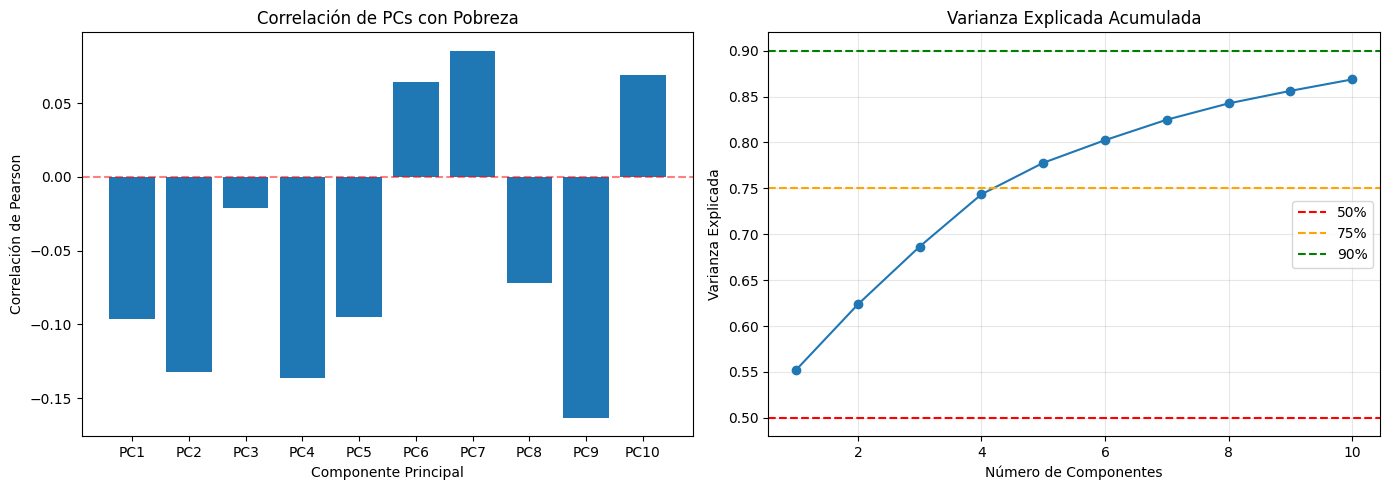


📊 Correlación máxima con pobreza: 0.1635 (PC9)


In [ ]:
# ================================================================
# ANÁLISIS DE CORRELACIONES: PCA vs POBREZA
# ================================================================

from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from scipy.stats import pearsonr
import matplotlib.pyplot as plt

# Usar el mejor embedding (SatMAE CLS)
emb = np.load('/content/drive/MyDrive/Embeddings_SatMAE/SatMAE_CLS_embeddings.npy')

# Escalar
scaler = StandardScaler()
X_scaled = scaler.fit_transform(emb)

# PCA
pca = PCA(n_components=10, random_state=42)
X_pca = pca.fit_transform(X_scaled)

# Correlación de cada componente con pobreza
correlaciones = []
for i in range(X_pca.shape[1]):
    corr, p_val = pearsonr(X_pca[:, i], y)
    correlaciones.append({
        'Componente': f'PC{i+1}',
        'Correlación': corr,
        'p-valor': p_val,
        'Varianza': pca.explained_variance_ratio_[i]
    })

df_corr = pd.DataFrame(correlaciones)

print("📊 CORRELACIÓN DE COMPONENTES PCA CON POBREZA")
print("="*60)
print(df_corr.round(4))

# Visualizar
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Gráfico 1: Correlaciones
ax1 = axes[0]
ax1.bar(df_corr['Componente'], df_corr['Correlación'])
ax1.axhline(0, color='red', linestyle='--', alpha=0.5)
ax1.set_title('Correlación de PCs con Pobreza')
ax1.set_ylabel('Correlación de Pearson')
ax1.set_xlabel('Componente Principal')

# Gráfico 2: Varianza explicada acumulada
ax2 = axes[1]
cum_var = np.cumsum(pca.explained_variance_ratio_)
ax2.plot(range(1, len(cum_var)+1), cum_var, 'o-')
ax2.axhline(0.5, color='red', linestyle='--', label='50%')
ax2.axhline(0.75, color='orange', linestyle='--', label='75%')
ax2.axhline(0.90, color='green', linestyle='--', label='90%')
ax2.set_title('Varianza Explicada Acumulada')
ax2.set_xlabel('Número de Componentes')
ax2.set_ylabel('Varianza Explicada')
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('/content/drive/MyDrive/Resultados_Benchmark_Final/correlaciones_pca.png', dpi=150)
plt.show()

print(f"\n📊 Correlación máxima con pobreza: {df_corr['Correlación'].abs().max():.4f} (PC{df_corr['Correlación'].abs().idxmax()+1})")

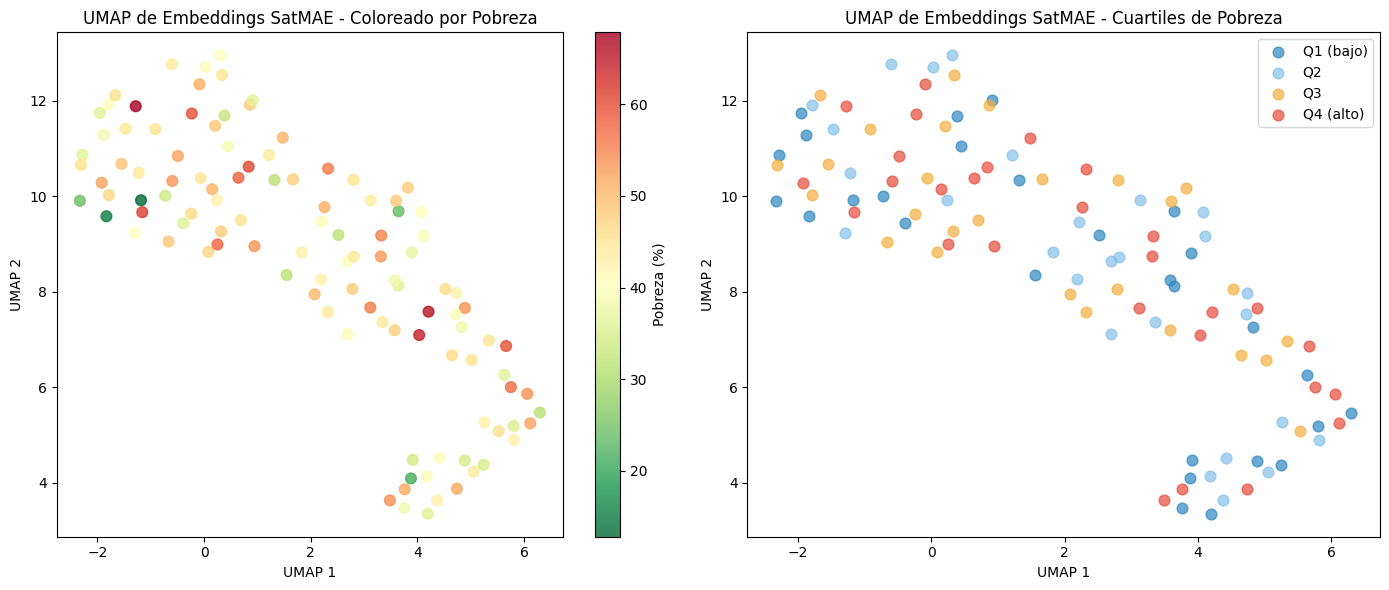


📊 DATOS UMAP
Embeddings shape: (110, 768)
Pobreza - Min: 12.8000, Max: 67.8500, Media: 44.2418
UMAP 1 - Min: -2.3263, Max: 6.2975
UMAP 2 - Min: 3.3489, Max: 12.9492

Cuartiles de pobreza:
  Q25: 39.3125
  Q50: 44.3250
  Q75: 50.5500
✅ UMAP visualizado y guardado


In [ ]:
# ================================================================
# VISUALIZACIÓN UMAP: EMBEDDINGS COLOREADOS POR POBREZA
# ================================================================

import umap
import matplotlib.pyplot as plt

# Usar SatMAE CLS
emb = np.load('/content/drive/MyDrive/Embeddings_SatMAE/SatMAE_CLS_embeddings.npy')

# UMAP a 2D
reducer = umap.UMAP(n_components=2, n_neighbors=15, min_dist=0.5, random_state=42)
emb_2d = reducer.fit_transform(emb)

# Visualizar
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Gráfico 1: Coloreado por pobreza (continuo)
ax1 = axes[0]
sc = ax1.scatter(emb_2d[:, 0], emb_2d[:, 1], c=y, cmap='RdYlGn_r', s=60, alpha=0.8)
plt.colorbar(sc, ax=ax1, label='Pobreza (%)')
ax1.set_title('UMAP de Embeddings SatMAE - Coloreado por Pobreza')
ax1.set_xlabel('UMAP 1')
ax1.set_ylabel('UMAP 2')

# Gráfico 2: Distribución de pobreza (cuantiles)
ax2 = axes[1]
y_quantiles = pd.qcut(y, q=4, labels=['Q1 (bajo)', 'Q2', 'Q3', 'Q4 (alto)'])
colors = ['#2E86C1', '#85C1E9', '#F5B041', '#E74C3C']
for i, label in enumerate(['Q1 (bajo)', 'Q2', 'Q3', 'Q4 (alto)']):
    mask = y_quantiles == label
    ax2.scatter(emb_2d[mask, 0], emb_2d[mask, 1],
                c=colors[i], label=label, s=60, alpha=0.7)
ax2.set_title('UMAP de Embeddings SatMAE - Cuartiles de Pobreza')
ax2.set_xlabel('UMAP 1')
ax2.set_ylabel('UMAP 2')
ax2.legend()

plt.tight_layout()
plt.savefig('/content/drive/MyDrive/Resultados_Benchmark_Final/umap_pobreza.png', dpi=150)
plt.show()

# Mostrar datos en consola
print("\n📊 DATOS UMAP")
print(f"Embeddings shape: {emb.shape}")
print(f"Pobreza - Min: {y.min():.4f}, Max: {y.max():.4f}, Media: {y.mean():.4f}")
print(f"UMAP 1 - Min: {emb_2d[:,0].min():.4f}, Max: {emb_2d[:,0].max():.4f}")
print(f"UMAP 2 - Min: {emb_2d[:,1].min():.4f}, Max: {emb_2d[:,1].max():.4f}")
print("\nCuartiles de pobreza:")
for q in [0.25, 0.5, 0.75]:
    print(f"  Q{int(q*100)}: {np.percentile(y, q*100):.4f}")

print("✅ UMAP visualizado y guardado")

  0%|          | 0/110 [00:00<?, ?it/s]

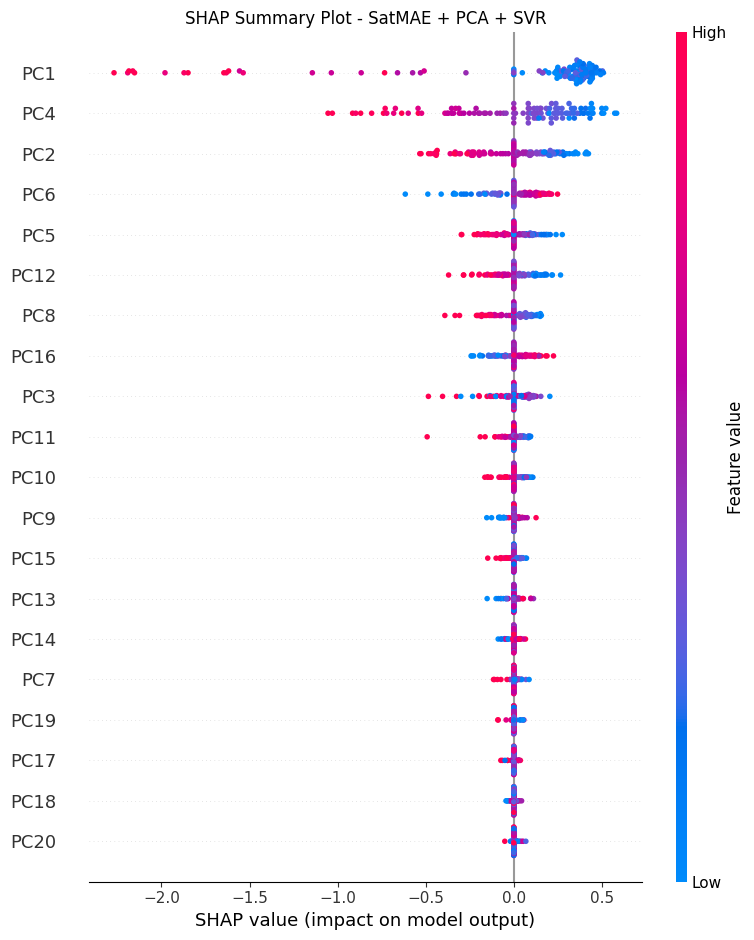

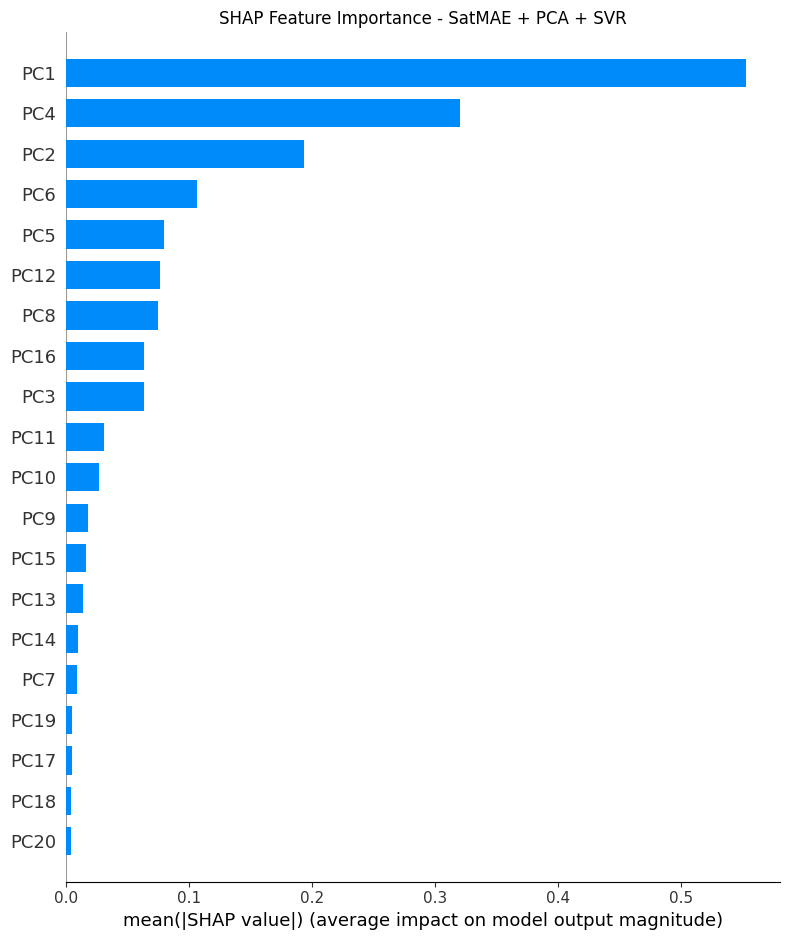


📊 TOP 10 COMPONENTES MÁS IMPORTANTES SEGÚN SHAP
  PC1: 0.5526
  PC4: 0.3200
  PC2: 0.1934
  PC6: 0.1062
  PC5: 0.0800
  PC12: 0.0767
  PC8: 0.0749
  PC16: 0.0635
  PC3: 0.0630
  PC11: 0.0311

📊 DATOS SHAP
Modelo SVR - R²: 0.0804
Muestra SHAP: 110 puntos
SHAP values shape: (110, 20)

📊 ESTADÍSTICAS SHAP VALUES
Media global: 0.0836
Máximo valor SHAP: 2.2693
Mínimo valor SHAP: 0.0000

📊 TOP 10 COMPONENTES MÁS IMPORTANTES SEGÚN SHAP
  PC1: 0.5526
  PC4: 0.3200
  PC2: 0.1934
  PC6: 0.1062
  PC5: 0.0800
  PC12: 0.0767
  PC8: 0.0749
  PC16: 0.0635
  PC3: 0.0630
  PC11: 0.0311


In [ ]:
# ================================================================
# SHAP: IMPORTANCIA DE VARIABLES SOBRE SATMAE + PCA + SVR
# ================================================================

!pip install shap -q

import shap
import numpy as np
import pandas as pd
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR
from sklearn.model_selection import train_test_split

# --- Datos ---
emb = np.load('/content/drive/MyDrive/Embeddings_SatMAE/SatMAE_CLS_embeddings.npy')

# Preprocesar
scaler = StandardScaler()
X_scaled = scaler.fit_transform(emb)
pca = PCA(n_components=20, random_state=42)  # 20 componentes para SHAP
X_pca = pca.fit_transform(X_scaled)

# Entrenar SVR
svr = SVR(kernel='rbf', C=1.0, gamma='scale')
svr.fit(X_pca, y)

# --- SHAP (usando TreeExplainer no funciona con SVR, usamos KernelExplainer) ---
# Para SVR necesitamos KernelExplainer (más lento pero funciona)

# Tomar una muestra pequeña para SHAP (150-200 puntos)
X_sample = X_pca[:min(150, len(X_pca))]

# Crear explainer
explainer = shap.KernelExplainer(svr.predict, X_sample)

# Calcular SHAP values (puede tomar 5-10 minutos)
shap_values = explainer.shap_values(X_sample, nsamples=100)

# --- Visualizar ---
feature_names = [f'PC{i+1}' for i in range(X_pca.shape[1])]

# Gráfico 1: Summary plot
plt.figure(figsize=(10, 8))
shap.summary_plot(shap_values, X_sample, feature_names=feature_names, show=False)
plt.title('SHAP Summary Plot - SatMAE + PCA + SVR')
plt.tight_layout()
plt.savefig('/content/drive/MyDrive/Resultados_Benchmark_Final/shap_summary.png', dpi=150, bbox_inches='tight')
plt.show()

# Gráfico 2: Bar plot (importancia global)
plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values, X_sample, feature_names=feature_names, plot_type='bar', show=False)
plt.title('SHAP Feature Importance - SatMAE + PCA + SVR')
plt.tight_layout()
plt.savefig('/content/drive/MyDrive/Resultados_Benchmark_Final/shap_importance.png', dpi=150, bbox_inches='tight')
plt.show()

# --- Importancia por variable ---
shap_importance = np.abs(shap_values).mean(axis=0)
top_indices = np.argsort(shap_importance)[::-1][:10]

print("\n📊 TOP 10 COMPONENTES MÁS IMPORTANTES SEGÚN SHAP")
print("="*60)
for i in top_indices:
    print(f"  {feature_names[i]}: {shap_importance[i]:.4f}")

# Mostrar datos en consola
print("\n📊 DATOS SHAP")
print(f"Modelo SVR - R²: {svr.score(X_pca, y):.4f}")
print(f"Muestra SHAP: {len(X_sample)} puntos")
print(f"SHAP values shape: {shap_values.shape}")

print("\n📊 ESTADÍSTICAS SHAP VALUES")
print(f"Media global: {np.abs(shap_values).mean():.4f}")
print(f"Máximo valor SHAP: {np.abs(shap_values).max():.4f}")
print(f"Mínimo valor SHAP: {np.abs(shap_values).min():.4f}")

print("\n📊 TOP 10 COMPONENTES MÁS IMPORTANTES SEGÚN SHAP")
print("="*60)
for i in top_indices[:10]:
    print(f"  {feature_names[i]}: {shap_importance[i]:.4f}")



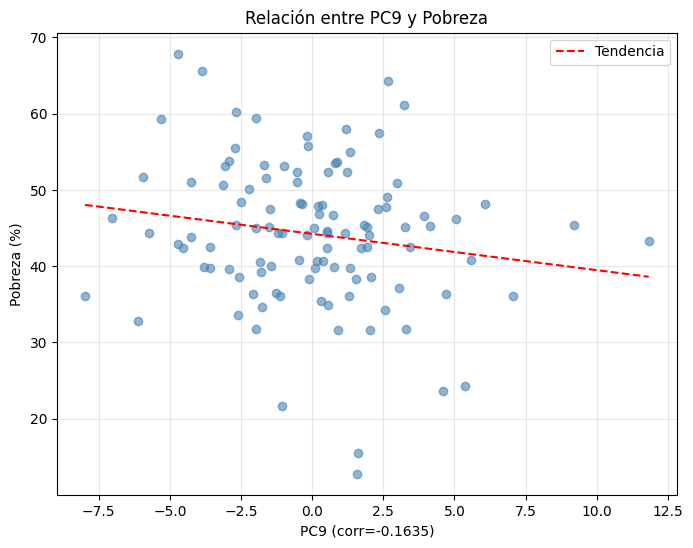


📊 SCATTER: PC vs POBREZA
Mejor PC: PC9
Correlación: -0.1635
P-valor: 0.0880
Varianza explicada: 0.0136

Estadísticas PC9:
  Min: -7.9768
  Max: 11.8255
  Media: -0.0000
  Std: 3.2370

Estadísticas Pobreza:
  Min: 12.8000
  Max: 67.8500
  Media: 44.2418
  Std: 9.4232

Tendencia (pendiente): -0.4758


In [ ]:
    # ================================================================
# SCATTER: EMBEDDING (MEJOR PC) vs POBREZA
# ================================================================

# Usar la PC con mayor correlación
best_pc_idx = df_corr['Correlación'].abs().idxmax()
best_pc = X_pca[:, best_pc_idx]

plt.figure(figsize=(8, 6))
plt.scatter(best_pc, y, alpha=0.6, c='steelblue')
plt.xlabel(f'PC{best_pc_idx+1} (corr={df_corr.loc[best_pc_idx, "Correlación"]:.4f})')
plt.ylabel('Pobreza (%)')
plt.title(f'Relación entre PC{best_pc_idx+1} y Pobreza')
plt.grid(True, alpha=0.3)

# Línea de tendencia
z = np.polyfit(best_pc, y, 1)
p = np.poly1d(z)
x_line = np.linspace(best_pc.min(), best_pc.max(), 100)
plt.plot(x_line, p(x_line), 'r--', label='Tendencia')
plt.legend()

plt.savefig('/content/drive/MyDrive/Resultados_Benchmark_Final/scatter_pc_vs_pobreza.png', dpi=150)
plt.show()


# Mostrar datos en consola
print("\n📊 SCATTER: PC vs POBREZA")
print(f"Mejor PC: PC{best_pc_idx+1}")
print(f"Correlación: {df_corr.loc[best_pc_idx, 'Correlación']:.4f}")
print(f"P-valor: {df_corr.loc[best_pc_idx, 'p-valor']:.4f}")
print(f"Varianza explicada: {df_corr.loc[best_pc_idx, 'Varianza']:.4f}")
print(f"\nEstadísticas PC{best_pc_idx+1}:")
print(f"  Min: {best_pc.min():.4f}")
print(f"  Max: {best_pc.max():.4f}")
print(f"  Media: {best_pc.mean():.4f}")
print(f"  Std: {best_pc.std():.4f}")
print(f"\nEstadísticas Pobreza:")
print(f"  Min: {y.min():.4f}")
print(f"  Max: {y.max():.4f}")
print(f"  Media: {y.mean():.4f}")
print(f"  Std: {y.std():.4f}")
print(f"\nTendencia (pendiente): {z[0]:.4f}")

**ETIQUETAS DE PREDICCION**

Mounted at /content/drive
📂 Cargando datos guardados...
✅ Embeddings: (110, 768)
✅ Etiquetas: 110 distritos

🔵 Entrenando SVR con PCA...

📊 RENDIMIENTO DEL MODELO
MAE: 6.9675 puntos porcentuales
R²:  0.0033


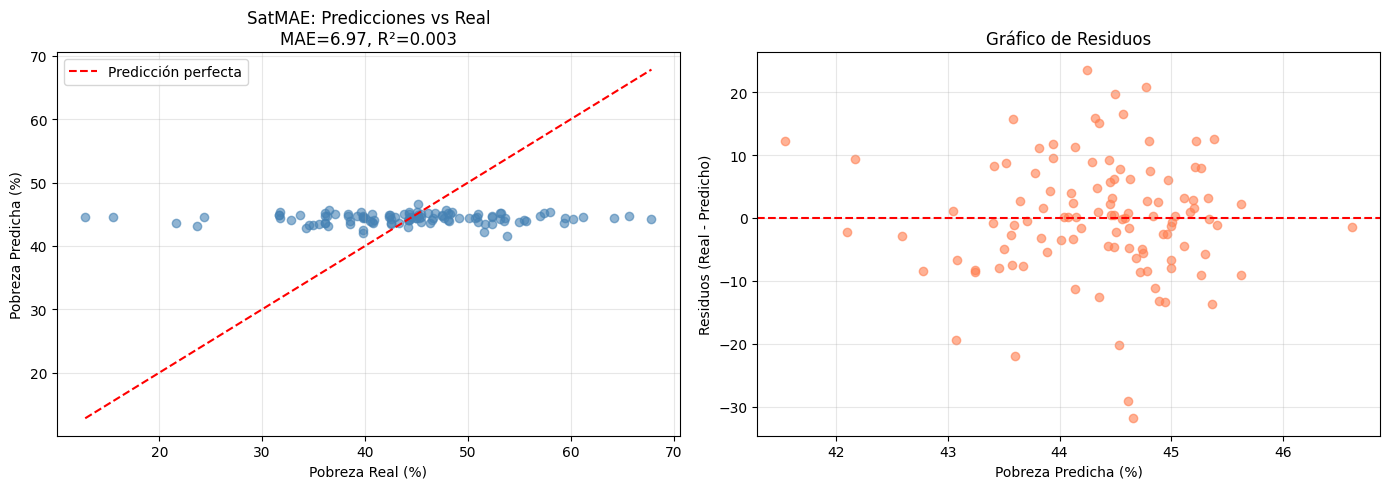


📋 EJEMPLOS DE PREDICCIONES

🔴 DISTRITOS CON MAYOR ERROR:
   distrito  pob_pct  predicho  error
0      PUNO    12.80     44.65  31.85
84   ANANEA    15.50     44.61  29.11
34   CORANI    67.85     44.25  23.60
88  JULIACA    21.65     43.60  21.95
33    COASA    65.65     44.77  20.88

🟢 DISTRITOS CON MENOR ERROR:
     distrito  pob_pct  predicho  error
37   OLLACHEA    44.55     44.59   0.04
105    COPANI    44.15     44.04   0.11
22     MUÑANI    44.30     44.15   0.15
35    CRUCERO    44.35     44.56   0.21
16     ACHAYA    44.30     44.07   0.23

📊 ESTADÍSTICAS DE ERRORES:
Error promedio: 6.97
Error mediano: 5.60
Error máximo: 31.85
Error mínimo: 0.04


In [1]:
# ================================================================
# CELDA INDEPENDIENTE: PREDICCIONES DE SATMAE
# ================================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.svm import SVR
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import mean_absolute_error, r2_score
from google.colab import drive

drive.mount('/content/drive')

# --- 1. Cargar datos guardados ---
print("📂 Cargando datos guardados...")

# Embeddings SatMAE
embeddings = np.load('/content/drive/MyDrive/Embeddings_SatMAE/SatMAE_CLS_embeddings.npy')

# Etiquetas de pobreza
df_pobreza = pd.read_csv('/content/drive/MyDrive/DL_DATASET_DISTRITOS/dataset_distritos.csv')
df_pobreza['ubigeo'] = df_pobreza['ubigeo'].astype(str).str.zfill(6)
y = df_pobreza['pob_pct'].values

print(f"✅ Embeddings: {embeddings.shape}")
print(f"✅ Etiquetas: {len(y)} distritos")

# --- 2. Preprocesar igual que en el pipeline ---
scaler = StandardScaler()
X_scaled = scaler.fit_transform(embeddings)

pca = PCA(n_components=50, random_state=42)
X_pca = pca.fit_transform(X_scaled)

# --- 3. Entrenar modelo SVR ---
print("\n🔵 Entrenando SVR con PCA...")
svr = SVR(kernel='rbf', C=1.0, gamma='scale')
svr.fit(X_pca, y)

# --- 4. Predicciones con cross-validation ---
y_pred = cross_val_predict(svr, X_pca, y, cv=5)

# --- 5. Métricas ---
mae = mean_absolute_error(y, y_pred)
r2 = r2_score(y, y_pred)

print(f"\n📊 RENDIMIENTO DEL MODELO")
print("="*60)
print(f"MAE: {mae:.4f} puntos porcentuales")
print(f"R²:  {r2:.4f}")

# --- 6. Gráfico: Predicciones vs Real ---
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Gráfico 1: Scatter
ax1 = axes[0]
ax1.scatter(y, y_pred, alpha=0.6, c='steelblue')
ax1.plot([y.min(), y.max()], [y.min(), y.max()], 'r--', label='Predicción perfecta')
ax1.set_xlabel('Pobreza Real (%)')
ax1.set_ylabel('Pobreza Predicha (%)')
ax1.set_title(f'SatMAE: Predicciones vs Real\nMAE={mae:.2f}, R²={r2:.3f}')
ax1.legend()
ax1.grid(True, alpha=0.3)

# Gráfico 2: Residuos
ax2 = axes[1]
residuos = y - y_pred
ax2.scatter(y_pred, residuos, alpha=0.6, c='coral')
ax2.axhline(0, color='red', linestyle='--')
ax2.set_xlabel('Pobreza Predicha (%)')
ax2.set_ylabel('Residuos (Real - Predicho)')
ax2.set_title('Gráfico de Residuos')
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# --- 7. Mostrar ejemplos de predicciones ---
print("\n📋 EJEMPLOS DE PREDICCIONES")
print("="*60)

# Crear DataFrame con resultados
resultados = df_pobreza[['ubigeo', 'distrito', 'pob_pct']].copy()
resultados['predicho'] = y_pred
resultados['error'] = abs(resultados['pob_pct'] - resultados['predicho'])

# Ordenar por error
print("\n🔴 DISTRITOS CON MAYOR ERROR:")
print(resultados.nlargest(5, 'error')[['distrito', 'pob_pct', 'predicho', 'error']].round(2))

print("\n🟢 DISTRITOS CON MENOR ERROR:")
print(resultados.nsmallest(5, 'error')[['distrito', 'pob_pct', 'predicho', 'error']].round(2))

print("\n📊 ESTADÍSTICAS DE ERRORES:")
print(f"Error promedio: {resultados['error'].mean():.2f}")
print(f"Error mediano: {resultados['error'].median():.2f}")
print(f"Error máximo: {resultados['error'].max():.2f}")
print(f"Error mínimo: {resultados['error'].min():.2f}")

In [3]:
# ================================================================
# CREAR CSV DE COMPARACIÓN: REAL vs PREDICHO (SatMAE)
# ================================================================

import pandas as pd
import os

# Crear DataFrame con comparación
df_comparacion = df_pobreza[['ubigeo', 'distrito', 'pob_pct']].copy()
df_comparacion['predicho_satmae'] = y_pred
df_comparacion['error_abs'] = abs(df_comparacion['pob_pct'] - df_comparacion['predicho_satmae'])
df_comparacion['error_pct'] = (df_comparacion['error_abs'] / df_comparacion['pob_pct']) * 100

# Ordenar por error absoluto (mayor a menor)
df_comparacion = df_comparacion.sort_values('error_abs', ascending=False)

# Guardar CSV
ruta_csv = '/content/drive/MyDrive/Resultados_Benchmark_Final/comparacion_satmae.csv'
os.makedirs(os.path.dirname(ruta_csv), exist_ok=True)
df_comparacion.to_csv(ruta_csv, index=False)

print(f"✅ CSV guardado en: {ruta_csv}")
print(f"📊 Shape: {df_comparacion.shape}")

# Mostrar primeras filas
print("\n📋 PRIMERAS 5 FILAS (mayor error):")
print(df_comparacion.head().round(2))

print("\n📊 ESTADÍSTICAS DEL ERROR:")
print(f"MAE: {df_comparacion['error_abs'].mean():.2f}")
print(f"Error máximo: {df_comparacion['error_abs'].max():.2f}")
print(f"Error mínimo: {df_comparacion['error_abs'].min():.2f}")
print(f"Error porcentual promedio: {df_comparacion['error_pct'].mean():.1f}%")

✅ CSV guardado en: /content/drive/MyDrive/Resultados_Benchmark_Final/comparacion_satmae.csv
📊 Shape: (110, 6)

📋 PRIMERAS 5 FILAS (mayor error):
    ubigeo distrito  pob_pct  predicho_satmae  error_abs  error_pct
0   210101     PUNO    12.80            44.65      31.85     248.86
84  211002   ANANEA    15.50            44.61      29.11     187.84
34  210305   CORANI    67.85            44.25      23.60      34.79
88  211101  JULIACA    21.65            43.60      21.95     101.38
33  210304    COASA    65.65            44.77      20.88      31.80

📊 ESTADÍSTICAS DEL ERROR:
MAE: 6.97
Error máximo: 31.85
Error mínimo: 0.04
Error porcentual promedio: 19.3%
